<a href="https://colab.research.google.com/github/n4hhh/K4-Track-4-Day10-VisionLanguageModel/blob/main/lab_day10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [ ]:
# Clone repository vào Colab
%cd /content
!git clone https://github.com/n4hhh/K4-Track-4-Day10-VisionLanguageModel.git

# Chuyển vào thư mục repository
%cd /content/K4-Track-4-Day10-VisionLanguageModel

# Kiểm tra GPU
!nvidia-smi -L

# Cài đặt dependencies
!pip -q install -r requirements-colab.txt

/content
Cloning into 'K4-Track-4-Day10-VisionLanguageModel'...
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 52 (delta 7), reused 1 (delta 1), pack-reused 38 (from 1)
Receiving objects: 100% (52/52), 2.68 MiB | 28.57 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/K4-Track-4-Day10-VisionLanguageModel
GPU 0: Tesla T4 (UUID: GPU-4fd9ce73-5e1c-ebff-955c-2266a80040dd)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 14.0 MB/s eta 0:00:00


In [ ]:
import os
from google.colab import userdata, drive
# Lấy credentials từ Colab Secrets
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
assert os.environ["KAGGLE_USERNAME"]
assert os.environ["KAGGLE_KEY"]
print("Kaggle credentials: OK")

# Mount Google Drive để lưu checkpoints
drive.mount("/content/drive")
print("Google Drive: OK")

Kaggle credentials: OK
Mounted at /content/drive
Google Drive: OK


## 1. Dữ liệu: tải và chia split

In [ ]:
!python scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:09<00:00, 20.1MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


In [ ]:
import json
from pathlib import Path

with open("data/splits/meta.json", encoding="utf-8") as f:
    meta = json.load(f)

print("Dataset version:", meta["dataset_version"])
print("\nSplit statistics:")

for split in ["train", "val", "test"]:
    path = Path(f"data/splits/{split}.jsonl")
    with path.open(encoding="utf-8") as f:
        records = [json.loads(line) for line in f]

    print(f"{split}: {len(records)} images")
    print("Boxes:", meta["counts"][split]["boxes"])

Dataset version: d10-21e4070301

Split statistics:
train: 1422 images
Boxes: {'pothole': 1074, 'crack': 1750, 'manhole': 691}
val: 276 images
Boxes: {'pothole': 66, 'crack': 470, 'manhole': 103}
test: 311 images
Boxes: {'pothole': 121, 'crack': 299, 'manhole': 163}


In [ ]:
!python -m pytest -q

...........................s.........................................    [100%]
68 passed, 1 skipped in 0.30s


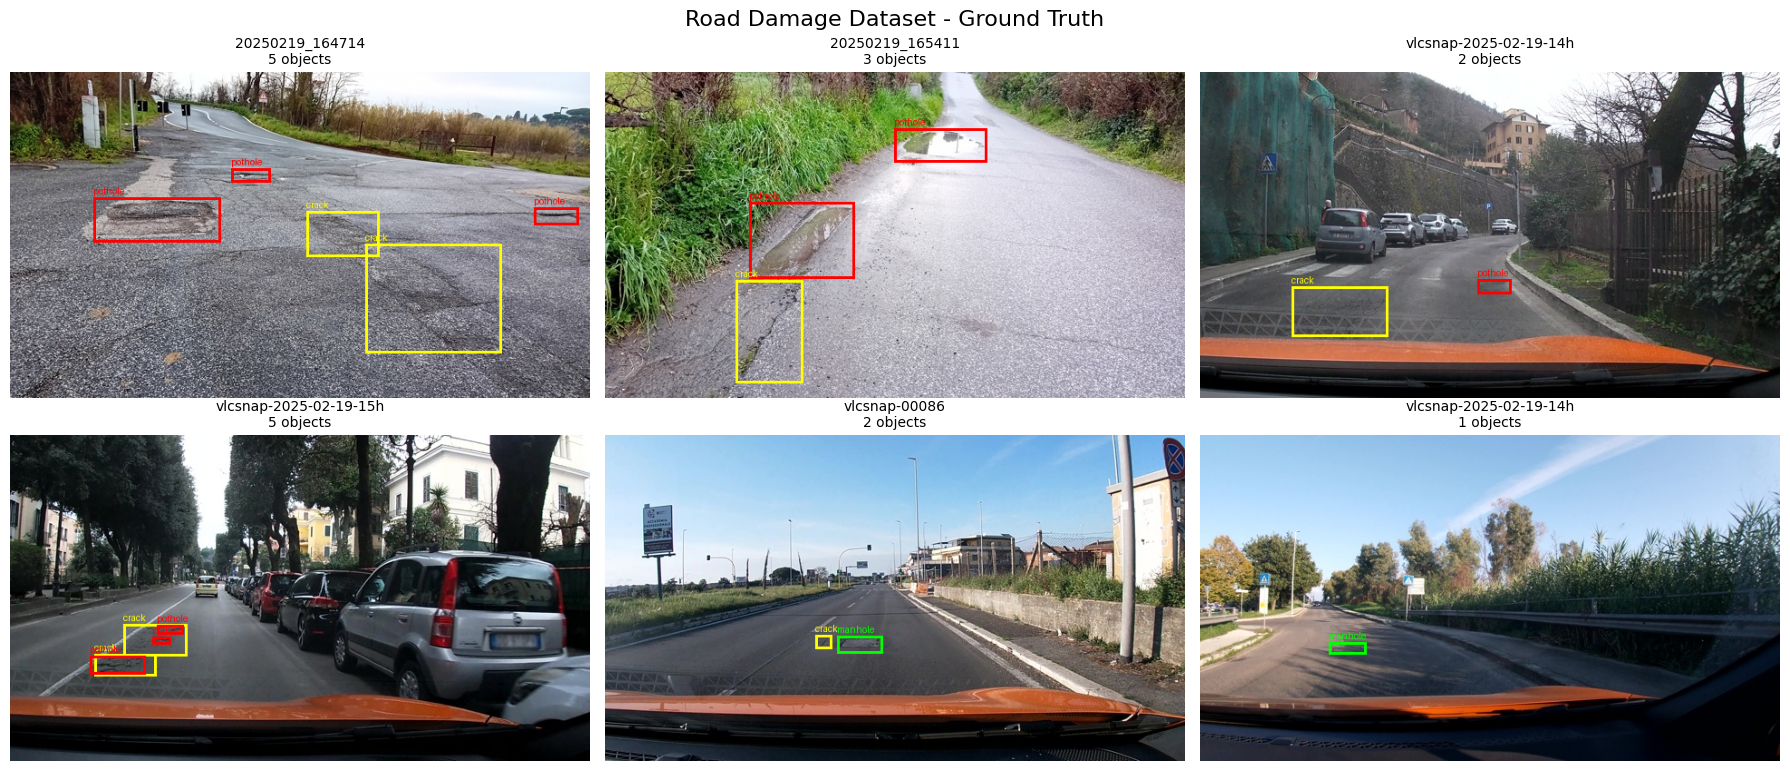

Visualized: 6 images
Saved: report/figures/ground_truth_samples.png


In [ ]:
import json
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from pathlib import Path

# Load train data
with open("data/splits/train.jsonl", encoding="utf-8") as f:
    train_data = [json.loads(line) for line in f]

COLORS = {
    "pothole": "red",
    "crack": "yellow",
    "manhole": "lime",
}

def draw_ground_truth(sample, ax):
    img_path = Path("data") / sample["image_path"]
    image = Image.open(img_path).convert("RGB")

    W, H = image.size
    draw = ImageDraw.Draw(image)

    for obj in sample["objects"]:
        label = obj["label"]
        xc, yc, w, h = obj["yolo"]

        # YOLO normalized -> pixel coordinates
        x1 = round((xc - w / 2) * W)
        y1 = round((yc - h / 2) * H)
        x2 = round((xc + w / 2) * W)
        y2 = round((yc + h / 2) * H)

        color = COLORS[label]

        draw.rectangle(
            [x1, y1, x2, y2],
            outline=color,
            width=3
        )

        draw.text(
            (x1, max(0, y1 - 13)),
            label,
            fill=color
        )

    ax.imshow(image)
    ax.set_title(
        f"{sample['image_id'][:22]}\n"
        f"{len(sample['objects'])} objects",
        fontsize=10
    )
    ax.axis("off")


# Chọn 2 ảnh chứa mỗi loại damage, không trùng ảnh
random.seed(42)
selected = []
selected_ids = set()

for label in COLORS:
    candidates = [
        s for s in train_data
        if any(o["label"] == label for o in s["objects"])
        and s["image_id"] not in selected_ids
    ]

    random.shuffle(candidates)

    for sample in candidates[:2]:
        selected.append(sample)
        selected_ids.add(sample["image_id"])

assert len(selected) == 6

# Plot
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for ax, sample in zip(axes.flat, selected):
    draw_ground_truth(sample, ax)

plt.suptitle(
    "Road Damage Dataset - Ground Truth",
    fontsize=16
)
plt.tight_layout()

# Save visualization
Path("report/figures").mkdir(parents=True, exist_ok=True)
plt.savefig(
    "report/figures/ground_truth_samples.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("Visualized:", len(selected), "images")
print("Saved: report/figures/ground_truth_samples.png")

In [ ]:
def get_sessions(split):
    with open(f"data/splits/{split}.jsonl", encoding="utf-8") as f:
        return {
            json.loads(line)["session"]
            for line in f
        }

train_sessions = get_sessions("train")
val_sessions = get_sessions("val")
test_sessions = get_sessions("test")

assert train_sessions.isdisjoint(val_sessions)
assert train_sessions.isdisjoint(test_sessions)
assert val_sessions.isdisjoint(test_sessions)

print("PASS: No session leakage!")
print("Train sessions:", len(train_sessions))
print("Val sessions:", len(val_sessions))
print("Test sessions:", len(test_sessions))

PASS: No session leakage!
Train sessions: 13
Val sessions: 2
Test sessions: 3


## 2. Nhãn: YOLO → JSON thang 0–1000

In [ ]:
import json

CLASSES = ("pothole", "crack", "manhole")

def yolo_to_box(label, yolo):
    assert label in CLASSES

    xc, yc, w, h = map(float, yolo)

    # YOLO normalized -> Grounding 0-1000
    x1 = round((xc - w / 2) * 1000)
    y1 = round((yc - h / 2) * 1000)
    x2 = round((xc + w / 2) * 1000)
    y2 = round((yc + h / 2) * 1000)

    # Clip coordinates
    x1 = max(0, min(999, x1))
    y1 = max(0, min(999, y1))
    x2 = max(0, min(1000, x2))
    y2 = max(0, min(1000, y2))

    # Prevent zero-area bounding boxes
    x2 = max(x1 + 1, x2)
    y2 = max(y1 + 1, y2)

    return {
        "label": label,
        "bbox_2d": [x1, y1, x2, y2]
    }


def objects_to_answer(objects):
    boxes = [
        yolo_to_box(obj["label"], obj["yolo"])
        for obj in objects
    ]

    # Deterministic ordering: top -> bottom, left -> right
    boxes.sort(
        key=lambda box: (
            box["bbox_2d"][1],
            box["bbox_2d"][0]
        )
    )

    return json.dumps(
        boxes,
        separators=(",", ":")
    )


# Quick test
example = train_data[0]

answer = objects_to_answer(example["objects"])

print("Image:", example["image_id"])
print("Grounding JSON:")
print(answer)

Image: 20250216_164325
Grounding JSON:
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


In [ ]:
# Check labels across all dataset splits
total_images = 0
total_boxes = 0

for split in ["train", "val", "test"]:
    with open(f"data/splits/{split}.jsonl", encoding="utf-8") as f:
        rows = [json.loads(line) for line in f]

    for sample in rows:
        answer = objects_to_answer(sample["objects"])
        boxes = json.loads(answer)

        assert len(boxes) == len(sample["objects"])

        # Check deterministic ordering
        assert boxes == sorted(
            boxes,
            key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0])
        )

        for box in boxes:
            x1, y1, x2, y2 = box["bbox_2d"]

            assert box["label"] in CLASSES
            assert all(
                isinstance(v, int)
                for v in box["bbox_2d"]
            )
            assert 0 <= x1 < x2 <= 1000
            assert 0 <= y1 < y2 <= 1000

        total_images += 1
        total_boxes += len(boxes)

assert total_images == 2009
assert total_boxes == 4737

print("PASS: Grounding JSON validation")
print("Total images:", total_images)
print("Total boxes:", total_boxes)

PASS: Grounding JSON validation
Total images: 2009
Total boxes: 4737


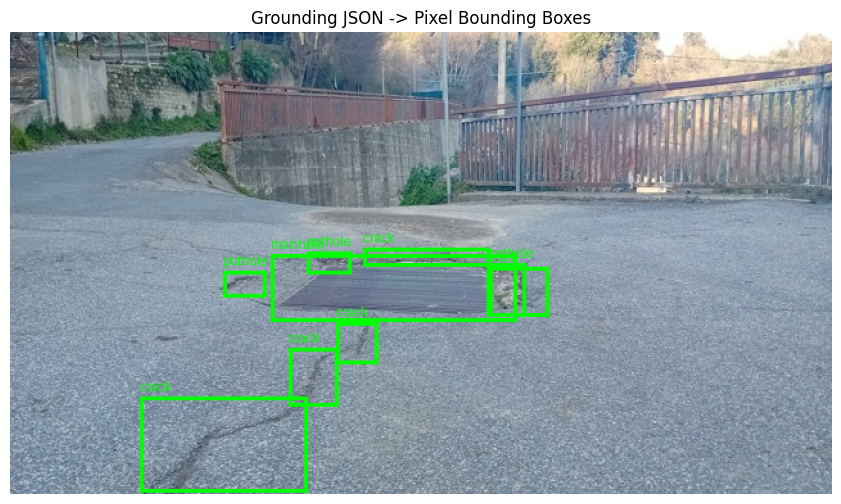

In [ ]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

sample = next(s for s in train_data if s["objects"])

image = Image.open(
    Path("data") / sample["image_path"]
).convert("RGB")

W, H = image.size
draw = ImageDraw.Draw(image)

for obj in json.loads(objects_to_answer(sample["objects"])):
    x1, y1, x2, y2 = obj["bbox_2d"]

    # 0-1000 -> pixels
    px = [
        round(x1 / 1000 * W),
        round(y1 / 1000 * H),
        round(x2 / 1000 * W),
        round(y2 / 1000 * H),
    ]

    draw.rectangle(px, outline="lime", width=3)
    draw.text(
        (px[0], max(0, px[1] - 14)),
        obj["label"],
        fill="lime"
    )

plt.figure(figsize=(12, 6))
plt.imshow(image)
plt.title("Grounding JSON -> Pixel Bounding Boxes")
plt.axis("off")
plt.show()

In [ ]:
PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d "
    "coordinates normalized on a 0-1000 scale: "
    '[{"label":"...","bbox_2d":[x1,y1,x2,y2]}]. '
    "If no damage is found, output []. "
    "Return JSON only, without explanations or markdown."
)

print(PROMPT)

Locate road damage in this image. Detect only objects of classes: pothole, crack, manhole. Output a JSON list of objects with label and bbox_2d coordinates normalized on a 0-1000 scale: [{"label":"...","bbox_2d":[x1,y1,x2,y2]}]. If no damage is found, output []. Return JSON only, without explanations or markdown.


## 3. E0: zero-shot

In [ ]:
import torch
import transformers
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
)

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

assert torch.cuda.is_available(), "Cần GPU T4"

print("Transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0))

quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=["model.visual", "lm_head"],
)

model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization,
    dtype=torch.float16,
    device_map={"": 0},
    attn_implementation="sdpa",
)

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"

model.eval()

# Xác minh các module thị giác không bị lượng tử hóa 4-bit
from bitsandbytes.nn import Linear4bit

quantized_visual = [
    name for name, module in model.named_modules()
    if ".visual." in f".{name}."
    and isinstance(module, Linear4bit)
]

quantized_head = [
    name for name, module in model.named_modules()
    if name.endswith("lm_head") and isinstance(module, Linear4bit)
]

assert not quantized_visual, "ViT/Projector đã bị quantize!"
assert not quantized_head, "lm_head đã bị quantize!"

print("MODEL LOADED SUCCESSFULLY")
print("ViT / Projector / lm_head: not 4-bit")
print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Transformers: 5.19.0
GPU: Tesla T4


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

MODEL LOADED SUCCESSFULLY
ViT / Projector / lm_head: not 4-bit
GPU allocated: 3.27 GB


In [ ]:
from bitsandbytes.nn import Linear4bit

visual_4bit = [
    name for name, module in model.named_modules()
    if name.startswith("model.visual.")
    and isinstance(module, Linear4bit)
]

llm_4bit = [
    name for name, module in model.named_modules()
    if name.startswith("model.language_model.")
    and isinstance(module, Linear4bit)
]

assert len(visual_4bit) == 0, visual_4bit[:10]
assert not isinstance(model.lm_head, Linear4bit)
assert len(llm_4bit) > 0

print("PASS: Visual backbone and projector are not quantized")
print("PASS: lm_head is not quantized")
print("PASS: LLM uses 4-bit layers")
print("LLM 4-bit modules:", len(llm_4bit))
print(
    "Allocated VRAM:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

PASS: Visual backbone and projector are not quantized
PASS: lm_head is not quantized
PASS: LLM uses 4-bit layers
LLM 4-bit modules: 252
Allocated VRAM: 3.27 GB


In [ ]:
from PIL import Image
from pathlib import Path
from scripts.labcommon import read_jsonl
from scripts.score import parse_output

test_data = read_jsonl("data/splits/test.jsonl")

assert len(test_data) == 311

def predict_one(sample, max_new_tokens=256):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": PROMPT},
            ],
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    # Một số processor sinh token_type_ids không dùng cho generation
    inputs.pop("token_type_ids", None)
    inputs = inputs.to(model.device)

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )

    new_tokens = output_ids[0, inputs["input_ids"].shape[1]:]

    raw = processor.decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return raw.strip()


sample = test_data[0]
raw = predict_one(sample)

print("Image ID:", sample["image_id"])
print("\nRaw prediction:\n", raw)
print("\nParsed:", parse_output(raw) is not None)

print(
    "\nPeak VRAM:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)

Image ID: vlcsnap-00200

Raw prediction:
 [{"label":"manhole","bbox_2d": [770, 640, 843, 687]}]

Parsed: True

Peak VRAM: 3.41 GB


In [ ]:
import json
import shutil
from pathlib import Path
from tqdm.auto import tqdm

out_path = Path("work/e0.jsonl")
out_path.parent.mkdir(parents=True, exist_ok=True)

backup_dir = Path("/content/drive/MyDrive/VinUni_Day10")
backup_dir.mkdir(parents=True, exist_ok=True)
backup_path = backup_dir / "e0.jsonl"

# Khôi phục kết quả khi Colab từng bị ngắt
if not out_path.exists() and backup_path.exists():
    shutil.copy2(backup_path, out_path)

seen = set()

if out_path.exists():
    with out_path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                seen.add(json.loads(line)["image_id"])

print("Already completed:", len(seen))

try:
    with out_path.open("a", encoding="utf-8") as f:
        for sample in tqdm(test_data, desc="E0 zero-shot"):
            image_id = sample["image_id"]

            if image_id in seen:
                continue

            raw = predict_one(sample)

            record = {
                "image_id": image_id,
                "raw": raw,
            }

            f.write(json.dumps(record, ensure_ascii=False) + "\n")
            f.flush()

            seen.add(image_id)

            if len(seen) % 10 == 0:
                shutil.copy2(out_path, backup_path)

finally:
    if out_path.exists():
        shutil.copy2(out_path, backup_path)

print("Completed:", len(seen), "/ 311")
print("Saved:", out_path)
print("Backup:", backup_path)

Already completed: 0


E0 zero-shot:   0%|          | 0/311 [00:00<?, ?it/s]

Completed: 311 / 311
Saved: work/e0.jsonl
Backup: /content/drive/MyDrive/VinUni_Day10/e0.jsonl


In [ ]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.849 P=0.124 R=0.070 F1=0.090 CI95=0.063-0.118 meanIoU=0.608 FP/img=0.93
   pothole  P=0.250 R=0.074 F1=0.115
   crack    P=0.033 R=0.023 F1=0.027
   manhole  P=0.316 R=0.153 F1=0.207


In [ ]:
import shutil
from pathlib import Path

backup_dir = Path("/content/drive/MyDrive/VinUni_Day10")
backup_dir.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    "report/evidence/e0.json",
    backup_dir / "e0.json"
)

print("E0 evidence backed up successfully")

E0 evidence backed up successfully


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [ ]:
import torch
from pathlib import Path
from PIL import Image

# Training dùng right-padding
processor.tokenizer.padding_side = "right"

def encode_example(sample):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as im:
        image = im.convert("RGB")

    answer = objects_to_answer(sample["objects"])

    user_msg = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }]

    full_msg = user_msg + [{
        "role": "assistant",
        "content": answer,
    }]

    # Encode chỉ phần prompt
    prompt_enc = processor.apply_chat_template(
        user_msg,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    # Encode prompt + câu trả lời JSON
    full_enc = processor.apply_chat_template(
        full_msg,
        tokenize=True,
        add_generation_prompt=False,
        return_dict=True,
        return_tensors="pt",
    )

    n_prompt = prompt_enc["input_ids"].shape[1]

    # Kiểm tra prefix trước khi mask
    assert torch.equal(
        full_enc["input_ids"][0, :n_prompt],
        prompt_enc["input_ids"][0]
    ), "Prompt prefix mismatch!"

    labels = full_enc["input_ids"].clone()

    # Bỏ qua prompt và image token khi tính loss
    labels[:, :n_prompt] = -100

    result = {
        "input_ids": full_enc["input_ids"][0],
        "attention_mask": full_enc["attention_mask"][0],
        "labels": labels[0],
        "pixel_values": full_enc["pixel_values"],
        "image_grid_thw": full_enc["image_grid_thw"],
    }

    # Qwen3-VL có thể trả thêm token type multimodal
    if "mm_token_type_ids" in full_enc:
        result["mm_token_type_ids"] = full_enc[
            "mm_token_type_ids"
        ][0]

    return result


def collate_fn(batch):
    from torch.nn.utils.rnn import pad_sequence

    pad_id = processor.tokenizer.pad_token_id
    assert pad_id is not None

    result = {
        "input_ids": pad_sequence(
            [b["input_ids"] for b in batch],
            batch_first=True,
            padding_value=pad_id,
        ),

        "attention_mask": pad_sequence(
            [b["attention_mask"] for b in batch],
            batch_first=True,
            padding_value=0,
        ),

        "labels": pad_sequence(
            [b["labels"] for b in batch],
            batch_first=True,
            padding_value=-100,
        ),

        # Không padding vision tensors
        "pixel_values": torch.cat(
            [b["pixel_values"] for b in batch],
            dim=0,
        ),

        "image_grid_thw": torch.cat(
            [b["image_grid_thw"] for b in batch],
            dim=0,
        ),
    }

    if all("mm_token_type_ids" in b for b in batch):
        result["mm_token_type_ids"] = pad_sequence(
            [b["mm_token_type_ids"] for b in batch],
            batch_first=True,
            padding_value=0,
        )

    return result

print("PASS: encode_example and collate_fn defined")

PASS: encode_example and collate_fn defined


In [ ]:
sample = train_data[0]
encoded = encode_example(sample)

input_ids = encoded["input_ids"]
labels = encoded["labels"]

prompt_tokens = int((labels == -100).sum())
answer_tokens = int((labels != -100).sum())

decoded_answer = processor.tokenizer.decode(
    input_ids[labels != -100].tolist(),
    skip_special_tokens=False,
    clean_up_tokenization_spaces=False,
)

print("Image ID:", sample["image_id"])
print("Total tokens:", len(input_ids))
print("Masked tokens:", prompt_tokens)
print("Answer tokens:", answer_tokens)

print("\nDecoded target:")
print(decoded_answer)

# Mask và target phải hợp lệ
assert prompt_tokens > 0
assert answer_tokens > 0
assert "bbox_2d" in decoded_answer
assert decoded_answer.startswith(
    objects_to_answer(sample["objects"])
)

assert decoded_answer.rstrip().endswith("<|im_end|>"), (
    f"Unexpected target ending: {repr(decoded_answer[-80:])}"
)

print("PASS: Assistant answer ends with <|im_end|>")

# Kiểm tra vision grid thực tế
grid = encoded["image_grid_thw"]
merge_size = model.config.vision_config.spatial_merge_size

vision_tokens = int(
    grid.prod(dim=1).sum().item()
    // (merge_size ** 2)
)

print("\nVision grid:", grid.tolist())
print("Vision tokens:", vision_tokens)

print("\nPASS: Autoregressive loss masking!")

Image ID: 20250216_164325
Total tokens: 566
Masked tokens: 316
Answer tokens: 250

Decoded target:
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>

PASS: Assistant answer ends with <|im_end|>

Vision grid: [[1, 22, 40]]
Vision tokens: 220

PASS: Autoregressive loss masking!


In [ ]:
sample_a = encode_example(train_data[0])
sample_b = encode_example(train_data[1])

batch = collate_fn([sample_a, sample_b])

for key, value in batch.items():
    print(f"{key}: {tuple(value.shape)}")

assert batch["input_ids"].shape[0] == 2
assert batch["labels"].shape == batch["input_ids"].shape
assert batch["attention_mask"].shape == batch["input_ids"].shape
assert batch["image_grid_thw"].shape == (2, 3)

# Padding không được tham gia tính loss
assert torch.all(
    batch["labels"][batch["attention_mask"] == 0] == -100
)

# Mỗi mẫu phải có assistant tokens dùng để train
assert torch.all((batch["labels"] != -100).sum(dim=1) > 0)

print("\nPASS: Multimodal collator!")

input_ids: (2, 566)
attention_mask: (2, 566)
labels: (2, 566)
pixel_values: (1760, 1536)
image_grid_thw: (2, 3)
mm_token_type_ids: (2, 566)

PASS: Multimodal collator!


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [ ]:
import re
import torch
from peft import LoraConfig, get_peft_model

def apply_setup(model, setup_name="E1"):
    assert setup_name == "E1", "Chỉ cấu hình E1 ở bước này"

    # 1. Đóng băng toàn bộ pretrained weights
    for param in model.parameters():
        param.requires_grad_(False)

    # 2. Chỉ chọn Attention và MLP thuộc LLM
    pattern = re.compile(
        r"model\.language_model\.layers\.\d+\."
        r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)"
        r"|mlp\.(?:gate_proj|up_proj|down_proj))"
    )

    targets = [
        name
        for name, module in model.named_modules()
        if pattern.fullmatch(name)
    ]

    print("Matched LLM modules:", len(targets))
    print("First targets:", targets[:7])

    # 36 layers × 7 modules
    assert len(targets) == 252, (
        f"Expected 252, got {len(targets)}"
    )

    # 3. LoRA configuration
    lora_config = LoraConfig(
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        target_modules=targets,
        bias="none",
        task_type="CAUSAL_LM",
    )

    # 4. Enable input gradients for checkpointing
    model.enable_input_require_grads()
    model.config.use_cache = False

    peft_model = get_peft_model(model, lora_config)

    peft_model.gradient_checkpointing_enable(
        gradient_checkpointing_kwargs={
            "use_reentrant": False
        }
    )

    peft_model.print_trainable_parameters()

    return peft_model

In [ ]:
model = apply_setup(model, "E1")

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("\nE1 TRAINABLE PARAMETERS")
print("Trainable:", f"{trainable_params:,}")
print("Total:", f"{total_params:,}")
print(
    "Trainable percentage:",
    f"{trainable_params / total_params * 100:.4f}%"
)

# E1 không được cập nhật ViT hoặc Projector
visual_trainable = [
    name for name, p in model.named_parameters()
    if "visual." in name and p.requires_grad
]

assert not visual_trainable, visual_trainable[:10]

print("\nPASS: E1 trains LLM LoRA only!")

Matched LLM modules: 252
First targets: ['model.language_model.layers.0.self_attn.q_proj', 'model.language_model.layers.0.self_attn.k_proj', 'model.language_model.layers.0.self_attn.v_proj', 'model.language_model.layers.0.self_attn.o_proj', 'model.language_model.layers.0.mlp.gate_proj', 'model.language_model.layers.0.mlp.up_proj', 'model.language_model.layers.0.mlp.down_proj']
trainable params: 33,030,144 || all params: 4,470,845,952 || trainable%: 0.7388

E1 TRAINABLE PARAMETERS
Trainable: 33,030,144
Total: 2,654,188,032
Trainable percentage: 1.2445%

PASS: E1 trains LLM LoRA only!


In [ ]:
import gc
import torch
import time

model.train()
model.config.use_cache = False

# Kiểm tra lại collator
samples = [
    encode_example(train_data[0]),
    encode_example(train_data[1]),
]

batch = collate_fn(samples)

assert batch["input_ids"].shape[0] == 2
assert batch["labels"].shape == batch["input_ids"].shape
assert torch.all(
    batch["labels"][batch["attention_mask"] == 0] == -100
)

batch = {k: v.to("cuda") for k, v in batch.items()}

model.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

scaler_test = torch.amp.GradScaler("cuda", init_scale=256)

start = time.perf_counter()

with torch.autocast("cuda", dtype=torch.float16):
    output = model(**batch)
    loss = output.loss

assert torch.isfinite(loss), f"Non-finite loss: {loss.item()}"

scaler_test.scale(loss).backward()

grad_count = sum(
    p.grad is not None
    for p in model.parameters()
    if p.requires_grad
)

assert grad_count > 0, "No LoRA gradients!"

print("PASS: Forward + Backward")
print("Initial loss:", round(loss.item(), 4))
print("Parameters with gradients:", grad_count)
print("Time:", round(time.perf_counter() - start, 2), "s")
print(
    "Peak VRAM:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)

model.zero_grad(set_to_none=True)
del batch, output, loss, samples
gc.collect()
torch.cuda.empty_cache()

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


PASS: Forward + Backward
Initial loss: 1.0619
Parameters with gradients: 504
Time: 3.48 s
Peak VRAM: 5.86 GB


## 6. Vòng huấn luyện

In [ ]:
import json
import time
import shutil
import torch
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import get_cosine_schedule_with_warmup
from tqdm.auto import tqdm

# ===== E1 CONFIG =====
MAX_STEPS = 300
BATCH_SIZE = 2
GRAD_ACCUM = 4
LEARNING_RATE = 2e-4
WARMUP_STEPS = 15
MAX_GRAD_NORM = 1.0

class RoadDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        return self.records[idx]


train_loader = DataLoader(
    RoadDataset(train_data),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    collate_fn=lambda samples: collate_fn(
        [encode_example(s) for s in samples]
    ),
)

params = [p for p in model.parameters() if p.requires_grad]

optimizer = torch.optim.AdamW(
    params,
    lr=LEARNING_RATE,
    weight_decay=0.0,
)

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=WARMUP_STEPS,
    num_training_steps=MAX_STEPS,
)

scaler = torch.amp.GradScaler("cuda", init_scale=256)

work_dir = Path("work")
drive_dir = Path("/content/drive/MyDrive/VinUni_Day10")

work_dir.mkdir(parents=True, exist_ok=True)
drive_dir.mkdir(parents=True, exist_ok=True)

trainable_count = sum(p.numel() for p in params)

def save_e1_checkpoint(step, elapsed_minutes, losses):
    # Adapter LoRA
    adapter_dir = work_dir / f"E1_adapter_step{step:03d}"
    model.save_pretrained(str(adapter_dir))

    shutil.copytree(
        adapter_dir,
        drive_dir / adapter_dir.name,
        dirs_exist_ok=True,
    )

    # Optimizer state dùng để khôi phục quá trình train
    state_path = work_dir / "e1_train_state_latest.pt"
    torch.save({
        "step": step,
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
    }, state_path)

    shutil.copy2(
        state_path,
        drive_dir / state_path.name,
    )

    run_info = {
        "setup": "E1",
        "completed_steps": step,
        "trainable_params": trainable_count,
        "peak_vram_gb": round(
            torch.cuda.max_memory_allocated() / 1024**3, 4
        ),
        "train_minutes": round(elapsed_minutes, 4),
        "batch_size": BATCH_SIZE,
        "gradient_accumulation_steps": GRAD_ACCUM,
        "lr": LEARNING_RATE,
        "loss_history": losses,
    }

    run_path = work_dir / "e1_run.json"
    run_path.write_text(
        json.dumps(run_info, indent=2),
        encoding="utf-8",
    )
    shutil.copy2(run_path, drive_dir / run_path.name)

    print(f"\n[CHECKPOINT] Step {step} saved to Google Drive")


model.train()
model.config.use_cache = False
optimizer.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

train_iterator = iter(train_loader)
loss_history = []
skipped_updates = 0
completed_steps = 0
started = time.perf_counter()

progress = tqdm(total=MAX_STEPS, desc="Training E1")

while completed_steps < MAX_STEPS:
    accumulated_loss = 0.0

    for micro_step in range(GRAD_ACCUM):
        try:
            batch = next(train_iterator)
        except StopIteration:
            train_iterator = iter(train_loader)
            batch = next(train_iterator)

        batch = {
            k: v.to("cuda", non_blocking=True)
            for k, v in batch.items()
        }

        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model(**batch)
            loss = outputs.loss

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at step {completed_steps + 1}"
            )

        accumulated_loss += loss.detach().float().item()

        scaler.scale(loss / GRAD_ACCUM).backward()

        del outputs, loss, batch

    scaler.unscale_(optimizer)
    grad_norm = torch.nn.utils.clip_grad_norm_(
        params, MAX_GRAD_NORM
    )

    old_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()

    optimizer.zero_grad(set_to_none=True)

    if scaler.get_scale() < old_scale:
        skipped_updates += 1
        continue

    scheduler.step()
    completed_steps += 1

    mean_loss = accumulated_loss / GRAD_ACCUM
    loss_history.append(round(mean_loss, 6))

    progress.update(1)
    progress.set_postfix(
        loss=f"{mean_loss:.4f}",
        lr=f"{scheduler.get_last_lr()[0]:.2e}",
    )

    if completed_steps % 10 == 0:
        print(
            f"Step {completed_steps}/{MAX_STEPS} | "
            f"Loss {mean_loss:.4f} | "
            f"Grad norm {float(grad_norm):.3f} | "
            f"VRAM {torch.cuda.max_memory_allocated()/1024**3:.2f} GB"
        )

    if completed_steps % 100 == 0:
        elapsed = (time.perf_counter() - started) / 60
        save_e1_checkpoint(
            completed_steps,
            elapsed,
            loss_history,
        )

progress.close()

print("\nE1 TRAINING COMPLETE")
print("Completed optimizer steps:", completed_steps)
print("Skipped updates:", skipped_updates)
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])
print(
    "Train minutes:",
    round((time.perf_counter() - started) / 60, 2)
)

Training E1:   0%|          | 0/300 [00:00<?, ?it/s]

Step 10/300 | Loss 0.8429 | Grad norm 0.642 | VRAM 5.90 GB
Step 20/300 | Loss 0.7668 | Grad norm 0.636 | VRAM 5.91 GB
Step 30/300 | Loss 0.6632 | Grad norm 0.393 | VRAM 5.99 GB
Step 40/300 | Loss 0.6512 | Grad norm 0.558 | VRAM 6.24 GB
Step 50/300 | Loss 0.6546 | Grad norm 0.309 | VRAM 6.24 GB
Step 60/300 | Loss 0.6519 | Grad norm 1.048 | VRAM 6.24 GB
Step 70/300 | Loss 0.5932 | Grad norm 0.502 | VRAM 6.24 GB
Step 80/300 | Loss 0.5903 | Grad norm 0.412 | VRAM 6.48 GB
Step 90/300 | Loss 0.6312 | Grad norm 0.392 | VRAM 6.48 GB
Step 100/300 | Loss 0.6102 | Grad norm 0.524 | VRAM 6.48 GB

[CHECKPOINT] Step 100 saved to Google Drive
Step 110/300 | Loss 0.6114 | Grad norm 0.438 | VRAM 6.48 GB
Step 120/300 | Loss 0.5928 | Grad norm 0.421 | VRAM 6.50 GB
Step 130/300 | Loss 0.6173 | Grad norm 0.446 | VRAM 6.50 GB
Step 140/300 | Loss 0.6327 | Grad norm 0.323 | VRAM 6.50 GB
Step 150/300 | Loss 0.6118 | Grad norm 0.281 | VRAM 6.75 GB
Step 160/300 | Loss 0.5897 | Grad norm 0.336 | VRAM 6.75 GB
Step

In [ ]:
import torch
from scripts.labcommon import read_jsonl
from scripts.score import parse_output

# Model đang nằm trong RAM là E1 đã finetune.
# Không load lại base model hoặc gắn thêm adapter.
assert hasattr(model, "peft_config"), "E1 LoRA adapter not found"

model.eval()
model.config.use_cache = True
processor.tokenizer.padding_side = "left"

val_data = read_jsonl("data/splits/val.jsonl")
test_data = read_jsonl("data/splits/test.jsonl")

print("E1 ready for inference")
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

# Thử 1 ảnh validation
raw = predict_one(val_data[0])

print("\nRaw output:\n", raw)
print("\nValid JSON:", parse_output(raw) is not None)

E1 ready for inference
Validation images: 276
Test images: 311

Raw output:
 [{"label":"crack","bbox_2d":[128,450,259,550]},{"label":"crack","bbox_2d":[394,461,544,550]},{"label":"crack","bbox_2d":[394,550,481,622]},{"label":"crack","bbox_2d":[128,553,309,750]}]

Valid JSON: True


## 7. Suy luận và chấm E1–E3

In [ ]:
import json
import shutil
from pathlib import Path
from tqdm.auto import tqdm

out_path = Path("work/e1.jsonl")
out_path.parent.mkdir(parents=True, exist_ok=True)

backup_dir = Path("/content/drive/MyDrive/VinUni_Day10")
backup_dir.mkdir(parents=True, exist_ok=True)
backup_path = backup_dir / "e1.jsonl"

# Resume predictions nếu bị ngắt
if not out_path.exists() and backup_path.exists():
    shutil.copy2(backup_path, out_path)

seen = set()

if out_path.exists():
    with out_path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                seen.add(json.loads(line)["image_id"])

print("Previously completed:", len(seen))

try:
    with out_path.open("a", encoding="utf-8") as f:
        for sample in tqdm(test_data, desc="E1 inference"):
            image_id = sample["image_id"]

            if image_id in seen:
                continue

            raw = predict_one(sample)

            record = {
                "image_id": image_id,
                "raw": raw,
            }

            f.write(json.dumps(record, ensure_ascii=False) + "\n")
            f.flush()

            seen.add(image_id)

            if len(seen) % 10 == 0:
                shutil.copy2(out_path, backup_path)

finally:
    if out_path.exists():
        shutil.copy2(out_path, backup_path)

assert len(seen) == 311, f"Only {len(seen)} predictions"

print("\nE1 INFERENCE COMPLETE")
print("Predictions:", len(seen))
print("Saved:", out_path)
print("Backup:", backup_path)

Previously completed: 0


E1 inference:   0%|          | 0/311 [00:00<?, ?it/s]


E1 INFERENCE COMPLETE
Predictions: 311
Saved: work/e1.jsonl
Backup: /content/drive/MyDrive/VinUni_Day10/e1.jsonl


In [ ]:
import json
import subprocess
import shutil
from pathlib import Path

run_info = json.loads(
    Path("work/e1_run.json").read_text(encoding="utf-8")
)

assert run_info["completed_steps"] == 300

cmd = [
    "python", "scripts/score.py",
    "--pred", "work/e1.jsonl",
    "--name", "E1",
    "--out", "report/evidence/e1.json",
]

for key in ["trainable_params", "peak_vram_gb", "train_minutes"]:
    cmd += ["--meta", f"{key}={run_info[key]}"]

subprocess.run(cmd, check=True)

# Sao lưu evidence lên Google Drive
shutil.copy2(
    "report/evidence/e1.json",
    "/content/drive/MyDrive/VinUni_Day10/e1.json"
)

print("\nE1 evidence saved!")


E1 evidence saved!


In [ ]:
import json
from pathlib import Path

e0 = json.loads(Path("report/evidence/e0.json").read_text())
e1 = json.loads(Path("report/evidence/e1.json").read_text())

print("=" * 45)
print("E0 vs E1 RESULTS")
print("=" * 45)

for name, result in [("E0", e0), ("E1", e1)]:
    print(f"\n{name}")
    print("F1:", round(result["micro"]["f1"], 4))
    print("CI95:", result["f1_ci95"])
    print("Parse valid:", round(result["parse_valid_rate"], 4))
    print("FP/image:", round(result["fp_per_image"], 4))
    print("Missing:", result["missing_predictions"])

    for label in ["pothole", "crack", "manhole"]:
        print(
            f"  {label}:",
            round(result["per_class"][label]["f1"], 4)
        )

improvement = e1["micro"]["f1"] - e0["micro"]["f1"]

print("\n" + "=" * 45)
print("RUBRIC CHECK")
print("=" * 45)

print("F1 improvement:", round(improvement, 4))
print("F1 +0.10:", improvement >= 0.10)
print("Parse valid >= 0.95:", e1["parse_valid_rate"] >= 0.95)
print("No missing:", e1["missing_predictions"] == 0)
print(
    "Dataset versions match:",
    e0["dataset_version"] == e1["dataset_version"]
)
print("Training metadata:", e1["meta"])

E0 vs E1 RESULTS

E0
F1: 0.0898
CI95: [0.06306306306306306, 0.11778029445073614]
Parse valid: 0.8489
FP/image: 0.9293
Missing: 0
  pothole: 0.1146
  crack: 0.0272
  manhole: 0.2066

E1
F1: 0.2767
CI95: [0.2382608695652174, 0.3176361957525392]
Parse valid: 0.9968
FP/image: 1.2701
Missing: 0
  pothole: 0.201
  crack: 0.1985
  manhole: 0.5364

RUBRIC CHECK
F1 improvement: 0.1868
F1 +0.10: True
Parse valid >= 0.95: True
No missing: True
Dataset versions match: True
Training metadata: {'trainable_params': 33030144, 'peak_vram_gb': 6.751, 'train_minutes': 38.672}


In [ ]:
from pathlib import Path

drive_dir = Path("/content/drive/MyDrive/VinUni_Day10")

required = [
    drive_dir / "E1_adapter_step300" / "adapter_config.json",
    drive_dir / "e0.json",
    drive_dir / "e1.json",
    drive_dir / "e1.jsonl",
    drive_dir / "e1_run.json",
]

for path in required:
    print("OK" if path.exists() else "MISSING", path.name)

assert all(p.exists() for p in required)
print("PASS: E1 backup verified")

OK adapter_config.json
OK e0.json
OK e1.json
OK e1.jsonl
OK e1_run.json
PASS: E1 backup verified


In [ ]:
import gc
import torch

for name in [
    "optimizer", "scheduler", "scaler",
    "scaler_test", "params",
    "train_loader", "train_iterator",
    "batch", "model"
]:
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

print(
    "Allocated VRAM:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Allocated VRAM: 0.02 GB


In [ ]:
from transformers import (
    Qwen3VLForConditionalGeneration,
    BitsAndBytesConfig,
)
from bitsandbytes.nn import Linear4bit

quant_e2 = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=["model.visual", "lm_head"],
)

model_e2 = Qwen3VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen3-VL-4B-Instruct",
    quantization_config=quant_e2,
    dtype=torch.float16,
    device_map={"": 0},
    attn_implementation="sdpa",
)

assert not any(
    isinstance(m, Linear4bit)
    for name, m in model_e2.named_modules()
    if name.startswith("model.visual.")
)

print("PASS: E2 base model loaded")

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

PASS: E2 base model loaded


In [ ]:
import re
import torch
from peft import LoraConfig, get_peft_model

def setup_e2(base_model):
    for p in base_model.parameters():
        p.requires_grad_(False)

    pattern = re.compile(
        r"model\.language_model\.layers\.\d+\."
        r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)"
        r"|mlp\.(?:gate_proj|up_proj|down_proj))"
    )

    targets = [
        name for name, _ in base_model.named_modules()
        if pattern.fullmatch(name)
    ]

    assert len(targets) == 252

    # Projector được giữ full precision
    base_model.model.visual.merger.float()
    base_model.model.visual.deepstack_merger_list.float()

    base_model.enable_input_require_grads()
    base_model.config.use_cache = False

    config = LoraConfig(
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        target_modules=targets,
        bias="none",
        task_type="CAUSAL_LM",
    )

    peft_model = get_peft_model(base_model, config)

    # PEFT đã freeze base weights; mở lại projector
    projector_count = 0

    for name, p in peft_model.named_parameters():
        if (
            ".visual.merger." in name
            or ".visual.deepstack_merger_list." in name
        ):
            assert p.dtype == torch.float32
            p.requires_grad_(True)
            projector_count += p.numel()

    assert 100_000_000 < projector_count < 120_000_000

    peft_model.gradient_checkpointing_enable(
        gradient_checkpointing_kwargs={
            "use_reentrant": False
        }
    )

    # Không mở nhầm ViT backbone
    wrong = [
        name for name, p in peft_model.named_parameters()
        if ".visual." in name
        and p.requires_grad
        and ".visual.merger." not in name
        and ".visual.deepstack_merger_list." not in name
    ]
    assert not wrong, wrong[:10]

    print("LoRA targets:", len(targets))
    print("Full projector params:", f"{projector_count:,}")
    peft_model.print_trainable_parameters()

    return peft_model


model_e2 = setup_e2(model_e2)
processor.tokenizer.padding_side = "right"

print("\nPASS: E2 setup completed!")

LoRA targets: 252
Full projector params: 109,105,152
trainable params: 142,135,296 || all params: 4,470,845,952 || trainable%: 3.1792

PASS: E2 setup completed!


In [ ]:
import torch
import time
import gc

model_e2.train()
model_e2.config.use_cache = False
processor.tokenizer.padding_side = "right"

# Phân biệt LoRA và Projector
named_trainable = [
    (n, p) for n, p in model_e2.named_parameters()
    if p.requires_grad
]

projector_params = [
    (n, p) for n, p in named_trainable
    if ".visual.merger." in n
    or ".visual.deepstack_merger_list." in n
]

lora_params = [
    (n, p) for n, p in named_trainable
    if "lora_A" in n or "lora_B" in n
]

assert len(projector_params) > 0
assert len(lora_params) > 0
assert all(p.dtype == torch.float32 for _, p in projector_params)

print("E2 trainable:", sum(p.numel() for _, p in named_trainable))
print("Projector:", sum(p.numel() for _, p in projector_params))
print("LoRA:", sum(p.numel() for _, p in lora_params))

# Batch size 2 như cấu hình đề
samples = [
    encode_example(train_data[0]),
    encode_example(train_data[1]),
]

batch = collate_fn(samples)
batch = {k: v.to("cuda") for k, v in batch.items()}

model_e2.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

scaler_e2_test = torch.amp.GradScaler(
    "cuda", init_scale=256
)

start = time.perf_counter()

with torch.autocast("cuda", dtype=torch.float16):
    outputs = model_e2(**batch)
    loss = outputs.loss

assert torch.isfinite(loss), f"Invalid loss: {loss.item()}"

scaler_e2_test.scale(loss).backward()

# Kiểm tra gradient hai khối
proj_grads = [
    p.grad for _, p in projector_params
    if p.grad is not None
]

lora_grads = [
    p.grad for _, p in lora_params
    if p.grad is not None
]

assert proj_grads, "Projector has no gradients!"
assert lora_grads, "LoRA has no gradients!"

assert all(torch.isfinite(g).all().item() for g in proj_grads)
assert all(torch.isfinite(g).all().item() for g in lora_grads)

print("\nPASS: E2 Forward + Backward")
print("Loss:", round(loss.item(), 4))
print("Projector gradient tensors:", len(proj_grads))
print("LoRA gradient tensors:", len(lora_grads))
print(
    "Projector gradient dtype:",
    proj_grads[0].dtype
)
print(
    "Peak VRAM:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)
print(
    "Time:",
    round(time.perf_counter() - start, 2),
    "seconds"
)

# Cleanup
model_e2.zero_grad(set_to_none=True)

del batch, outputs, loss, samples
del proj_grads, lora_grads
gc.collect()
torch.cuda.empty_cache()

E2 trainable: 142135296
Projector: 109105152
LoRA: 33030144

PASS: E2 Forward + Backward
Loss: 1.0619
Projector gradient tensors: 24
LoRA gradient tensors: 504
Projector gradient dtype: torch.float32
Peak VRAM: 6.35 GB
Time: 2.66 seconds


In [ ]:
import json
import time
import shutil
import torch
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import get_cosine_schedule_with_warmup
from tqdm.auto import tqdm

# ============================================
# E2 CONFIG
# ============================================

E2_STEPS = 300
E2_BATCH_SIZE = 2
E2_GRAD_ACCUM = 4
E2_LR = 2e-4
E2_WARMUP = 15
E2_MAX_GRAD_NORM = 1.0

WORK_DIR = Path("work")
DRIVE_DIR = Path("/content/drive/MyDrive/VinUni_Day10")

WORK_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

assert hasattr(model_e2, "peft_config")
assert not (WORK_DIR / "e2_run.json").exists(), (
    "E2 checkpoint đã tồn tại. "
    "Không tự train lại từ đầu; cần kiểm tra trạng thái."
)

# ============================================
# DATA
# ============================================

class RoadDatasetE2(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        return self.records[idx]


processor.tokenizer.padding_side = "right"

e2_loader = DataLoader(
    RoadDatasetE2(train_data),
    batch_size=E2_BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    collate_fn=lambda samples: collate_fn(
        [encode_example(s) for s in samples]
    ),
)

# ============================================
# TRAINABLE PARAMETERS
# ============================================

e2_params = [
    p for p in model_e2.parameters()
    if p.requires_grad
]

e2_trainable_count = sum(
    p.numel() for p in e2_params
)

assert e2_trainable_count == 142135296

# ============================================
# OPTIMIZER + SCHEDULER
# ============================================

e2_optimizer = torch.optim.AdamW(
    e2_params,
    lr=E2_LR,
    weight_decay=0.0,
)

e2_scheduler = get_cosine_schedule_with_warmup(
    e2_optimizer,
    num_warmup_steps=E2_WARMUP,
    num_training_steps=E2_STEPS,
)

e2_scaler = torch.amp.GradScaler(
    "cuda",
    init_scale=256,
)

# ============================================
# SAVE ADAPTER + PROJECTOR + METADATA
# ============================================

def save_e2_checkpoint(step, elapsed_minutes, losses):
    print(f"\nSaving E2 checkpoint at step {step}...")

    # 1. Save LoRA adapter
    adapter_dir = WORK_DIR / f"E2_adapter_step{step}"

    model_e2.save_pretrained(str(adapter_dir))

    shutil.copytree(
        adapter_dir,
        DRIVE_DIR / adapter_dir.name,
        dirs_exist_ok=True,
    )

    # 2. Save FULL trained projector separately
    projector_state = {
        name: p.detach().cpu().clone()
        for name, p in model_e2.named_parameters()
        if (
            ".visual.merger." in name
            or ".visual.deepstack_merger_list." in name
        )
    }

    assert sum(
        t.numel() for t in projector_state.values()
    ) == 109105152

    projector_path = (
        WORK_DIR / f"E2_projector_step{step}.pt"
    )

    torch.save(projector_state, projector_path)

    shutil.copy2(
        projector_path,
        DRIVE_DIR / projector_path.name,
    )

    del projector_state

    # 3. Save training metadata
    run_info = {
        "setup": "E2",
        "completed_steps": step,
        "trainable_params": e2_trainable_count,
        "peak_vram_gb": round(
            torch.cuda.max_memory_allocated() / 1024**3,
            4,
        ),
        "train_minutes": round(elapsed_minutes, 4),
        "batch_size": E2_BATCH_SIZE,
        "gradient_accumulation_steps": E2_GRAD_ACCUM,
        "lr": E2_LR,
        "loss_history": losses,
    }

    run_path = WORK_DIR / "e2_run.json"

    run_path.write_text(
        json.dumps(run_info, indent=2),
        encoding="utf-8",
    )

    shutil.copy2(
        run_path,
        DRIVE_DIR / run_path.name,
    )

    # 4. Save optimizer/scheduler for recovery.
    # File này có thể lớn vì Projector được train FP32.
    state_path = WORK_DIR / "e2_train_state_latest.pt"

    torch.save(
        {
            "step": step,
            "optimizer": e2_optimizer.state_dict(),
            "scheduler": e2_scheduler.state_dict(),
            "scaler": e2_scaler.state_dict(),
        },
        state_path,
    )

    shutil.copy2(
        state_path,
        DRIVE_DIR / state_path.name,
    )

    print(f"[CHECKPOINT] E2 step {step} saved!")
    print(f"Projector: {projector_path.name}")


# ============================================
# TRAIN LOOP
# ============================================

model_e2.train()
model_e2.config.use_cache = False

e2_optimizer.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

e2_iterator = iter(e2_loader)

e2_losses = []
e2_completed = 0
e2_skipped = 0

e2_started = time.perf_counter()

pbar = tqdm(total=E2_STEPS, desc="Training E2")

while e2_completed < E2_STEPS:

    accumulated_loss = 0.0

    for micro_step in range(E2_GRAD_ACCUM):

        try:
            batch = next(e2_iterator)
        except StopIteration:
            e2_iterator = iter(e2_loader)
            batch = next(e2_iterator)

        batch = {
            k: v.to("cuda", non_blocking=True)
            for k, v in batch.items()
        }

        with torch.autocast(
            "cuda", dtype=torch.float16
        ):
            outputs = model_e2(**batch)
            loss = outputs.loss

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"E2 non-finite loss at step "
                f"{e2_completed + 1}"
            )

        accumulated_loss += loss.detach().float().item()

        e2_scaler.scale(
            loss / E2_GRAD_ACCUM
        ).backward()

        del outputs, loss, batch

    # Gradient clipping
    e2_scaler.unscale_(e2_optimizer)

    grad_norm = torch.nn.utils.clip_grad_norm_(
        e2_params,
        E2_MAX_GRAD_NORM,
    )

    old_scale = e2_scaler.get_scale()

    e2_scaler.step(e2_optimizer)
    e2_scaler.update()

    e2_optimizer.zero_grad(set_to_none=True)

    # Skip scheduler step if GradScaler skipped optimizer
    if e2_scaler.get_scale() < old_scale:
        e2_skipped += 1
        if e2_skipped > 20:
            raise RuntimeError(
                "Too many skipped E2 optimizer updates"
            )
        continue

    e2_scheduler.step()
    e2_completed += 1

    mean_loss = accumulated_loss / E2_GRAD_ACCUM
    e2_losses.append(round(mean_loss, 6))

    pbar.update(1)
    pbar.set_postfix(
        loss=f"{mean_loss:.4f}",
        lr=f"{e2_scheduler.get_last_lr()[0]:.2e}",
    )

    if e2_completed % 10 == 0:
        print(
            f"Step {e2_completed}/{E2_STEPS} | "
            f"Loss {mean_loss:.4f} | "
            f"Grad norm {float(grad_norm):.3f} | "
            f"VRAM "
            f"{torch.cuda.max_memory_allocated()/1024**3:.2f} GB"
        )

    if e2_completed % 100 == 0:
        elapsed = (
            time.perf_counter() - e2_started
        ) / 60

        save_e2_checkpoint(
            e2_completed,
            elapsed,
            e2_losses,
        )

pbar.close()

print("\nE2 TRAINING COMPLETE")
print("Completed steps:", e2_completed)
print("Skipped updates:", e2_skipped)
print("Initial loss:", e2_losses[0])
print("Final loss:", e2_losses[-1])
print(
    "Peak VRAM:",
    round(torch.cuda.max_memory_allocated()/1024**3, 2),
    "GB"
)
print(
    "Training minutes:",
    round((time.perf_counter()-e2_started)/60, 2)
)

Training E2:   0%|          | 0/300 [00:00<?, ?it/s]

Step 10/300 | Loss 0.7751 | Grad norm 1.058 | VRAM 7.55 GB
Step 20/300 | Loss 0.7222 | Grad norm 0.995 | VRAM 8.06 GB
Step 30/300 | Loss 0.6910 | Grad norm 0.700 | VRAM 8.06 GB
Step 40/300 | Loss 0.6113 | Grad norm 0.421 | VRAM 8.06 GB
Step 50/300 | Loss 0.6569 | Grad norm 0.509 | VRAM 8.06 GB
Step 60/300 | Loss 0.6481 | Grad norm 0.584 | VRAM 8.06 GB
Step 70/300 | Loss 0.6302 | Grad norm 0.442 | VRAM 8.44 GB
Step 80/300 | Loss 0.6506 | Grad norm 0.437 | VRAM 8.44 GB
Step 90/300 | Loss 0.6139 | Grad norm 3.771 | VRAM 8.44 GB
Step 100/300 | Loss 0.5907 | Grad norm 0.570 | VRAM 8.44 GB

Saving E2 checkpoint at step 100...
[CHECKPOINT] E2 step 100 saved!
Projector: E2_projector_step100.pt
Step 110/300 | Loss 0.5942 | Grad norm 0.745 | VRAM 8.44 GB
Step 120/300 | Loss 0.6043 | Grad norm 0.373 | VRAM 8.44 GB
Step 130/300 | Loss 0.5835 | Grad norm 1.804 | VRAM 8.44 GB
Step 140/300 | Loss 0.6288 | Grad norm 0.882 | VRAM 8.44 GB
Step 150/300 | Loss 0.6292 | Grad norm 0.447 | VRAM 8.44 GB
Step 

In [ ]:
from pathlib import Path
import json

drive_dir = Path("/content/drive/MyDrive/VinUni_Day10")

required = [
    "E2_adapter_step300/adapter_config.json",
    "E2_projector_step300.pt",
    "e2_run.json",
    "e2_train_state_latest.pt",
]

for file in required:
    path = drive_dir / file
    assert path.exists(), f"Missing {file}"
    print("PASS:", file)

run = json.loads(
    (drive_dir / "e2_run.json").read_text()
)

assert run["completed_steps"] == 300
assert run["trainable_params"] == 142135296

print("\nE2 TRAINING BACKUP VERIFIED")
print("Peak VRAM:", run["peak_vram_gb"])
print("Train minutes:", run["train_minutes"])

PASS: E2_adapter_step300/adapter_config.json
PASS: E2_projector_step300.pt
PASS: e2_run.json
PASS: e2_train_state_latest.pt

E2 TRAINING BACKUP VERIFIED
Peak VRAM: 8.4431
Train minutes: 41.3106


In [ ]:
import torch
from PIL import Image
from pathlib import Path
from scripts.labcommon import read_jsonl
from scripts.score import parse_output

assert hasattr(model_e2, "peft_config")

model_e2.eval()
model_e2.config.use_cache = True
processor.tokenizer.padding_side = "left"

test_data = read_jsonl("data/splits/test.jsonl")
val_data = read_jsonl("data/splits/val.jsonl")

def predict_e2(sample, max_new_tokens=256):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs.pop("token_type_ids", None)
    inputs = inputs.to("cuda")

    # E2 cần autocast vì Projector được giữ ở FP32
    with torch.inference_mode():
        with torch.autocast("cuda", dtype=torch.float16):
            output_ids = model_e2.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
            )

    new_tokens = output_ids[
        0, inputs["input_ids"].shape[1]:
    ]

    raw = processor.decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return raw.strip()


# Smoke test trên validation
raw = predict_e2(val_data[0])

print("Image:", val_data[0]["image_id"])
print("Raw prediction:", raw)
print("Valid JSON:", parse_output(raw) is not None)

print(
    "VRAM:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Image: vlcsnap-2025-02-18-18h30m17s408
Raw prediction: [{"label":"crack","bbox_2d":[14,453,250,550]},{"label":"crack","bbox_2d":[366,489,586,633]},{"label":"crack","bbox_2d":[100,503,250,750]}]
Valid JSON: True
VRAM: 4.67 GB


In [ ]:
import json
import shutil
from pathlib import Path
from tqdm.auto import tqdm

out_path = Path("work/e2.jsonl")
out_path.parent.mkdir(parents=True, exist_ok=True)

backup_dir = Path("/content/drive/MyDrive/VinUni_Day10")
backup_dir.mkdir(parents=True, exist_ok=True)

backup_path = backup_dir / "e2.jsonl"

# Resume từ backup nếu Colab bị ngắt
if not out_path.exists() and backup_path.exists():
    shutil.copy2(backup_path, out_path)

seen = set()

if out_path.exists():
    with out_path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                image_id = record["image_id"]

                assert image_id not in seen, (
                    f"Duplicate image: {image_id}"
                )
                seen.add(image_id)

expected_ids = {s["image_id"] for s in test_data}
assert seen <= expected_ids

print("Previously completed:", len(seen))

try:
    with out_path.open("a", encoding="utf-8") as f:
        for sample in tqdm(test_data, desc="E2 inference"):
            image_id = sample["image_id"]

            if image_id in seen:
                continue

            raw = predict_e2(sample)

            record = {
                "image_id": image_id,
                "raw": raw,
            }

            f.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )
            f.flush()

            seen.add(image_id)

            if len(seen) % 10 == 0:
                shutil.copy2(out_path, backup_path)

finally:
    if out_path.exists():
        shutil.copy2(out_path, backup_path)

assert seen == expected_ids

print("\nE2 INFERENCE COMPLETE")
print("Predictions:", len(seen))
print("Saved:", out_path)
print("Backup:", backup_path)

Previously completed: 0


E2 inference:   0%|          | 0/311 [00:00<?, ?it/s]


E2 INFERENCE COMPLETE
Predictions: 311
Saved: work/e2.jsonl
Backup: /content/drive/MyDrive/VinUni_Day10/e2.jsonl


In [ ]:
import json
import subprocess
import shutil
from pathlib import Path

run_info = json.loads(
    Path("work/e2_run.json").read_text(
        encoding="utf-8"
    )
)

assert run_info["completed_steps"] == 300
assert run_info["trainable_params"] == 142135296

cmd = [
    "python", "scripts/score.py",
    "--pred", "work/e2.jsonl",
    "--name", "E2",
    "--out", "report/evidence/e2.json",
]

for key in [
    "trainable_params",
    "peak_vram_gb",
    "train_minutes"
]:
    cmd += ["--meta", f"{key}={run_info[key]}"]

subprocess.run(cmd, check=True)

shutil.copy2(
    "report/evidence/e2.json",
    "/content/drive/MyDrive/VinUni_Day10/e2.json"
)

print("PASS: E2 evidence saved!")

PASS: E2 evidence saved!


In [ ]:
import json
from pathlib import Path

results = {}

for name in ["e0", "e1", "e2"]:
    path = Path(f"report/evidence/{name}.json")
    results[name] = json.loads(
        path.read_text(encoding="utf-8")
    )

assert len({
    r["dataset_version"]
    for r in results.values()
}) == 1

print("=" * 55)
print("E0 vs E1 vs E2")
print("=" * 55)

for name, r in results.items():
    print(f"\n{name.upper()}")
    print("F1:", round(r["micro"]["f1"], 4))
    print("CI95:", r["f1_ci95"])
    print("Parse valid:", round(r["parse_valid_rate"], 4))
    print("FP/image:", round(r["fp_per_image"], 4))
    print("Missing:", r["missing_predictions"])

    for label in ["pothole", "crack", "manhole"]:
        print(
            label,
            round(r["per_class"][label]["f1"], 4)
        )

e1 = results["e1"]
e2 = results["e2"]

print("\n" + "=" * 55)
print("E2 vs E1 IMPROVEMENT")
print("=" * 55)

delta = e2["micro"]["f1"] - e1["micro"]["f1"]

print("F1 delta:", round(delta, 4))
print("E2 better than E1:", delta > 0)
print("E2 parse valid >= 0.95:", e2["parse_valid_rate"] >= 0.95)
print("E2 missing predictions:", e2["missing_predictions"])
print("E2 metadata:", e2["meta"])

E0 vs E1 vs E2

E0
F1: 0.0898
CI95: [0.06306306306306306, 0.11778029445073614]
Parse valid: 0.8489
FP/image: 0.9293
Missing: 0
pothole 0.1146
crack 0.0272
manhole 0.2066

E1
F1: 0.2767
CI95: [0.2382608695652174, 0.3176361957525392]
Parse valid: 0.9968
FP/image: 1.2701
Missing: 0
pothole 0.201
crack 0.1985
manhole 0.5364

E2
F1: 0.3473
CI95: [0.3100358422939068, 0.3859964093357271]
Parse valid: 1.0
FP/image: 1.1093
Missing: 0
pothole 0.2381
crack 0.2833
manhole 0.5827

E2 vs E1 IMPROVEMENT
F1 delta: 0.0706
E2 better than E1: True
E2 parse valid >= 0.95: True
E2 missing predictions: 0
E2 metadata: {'trainable_params': 142135296, 'peak_vram_gb': 8.4431, 'train_minutes': 41.3106}


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

root = Path("/content/drive/MyDrive/VinUni_Day10")

files = [
    "e0.json",
    "e1.json",
    "e2.json",
    "e0.jsonl",
    "e1.jsonl",
    "e2.jsonl",
    "e1_run.json",
    "e2_run.json",
    "E1_adapter_step300/adapter_config.json",
    "E2_adapter_step300/adapter_config.json",
    "E2_projector_step300.pt",
]

for name in files:
    path = root / name
    print(
        "✅ OK" if path.is_file() else "❌ MISSING",
        name
    )

assert all((root / name).is_file() for name in files)
print("\nALL EXPERIMENT BACKUPS VERIFIED")

Mounted at /content/drive
✅ OK e0.json
✅ OK e1.json
✅ OK e2.json
✅ OK e0.jsonl
✅ OK e1.jsonl
✅ OK e2.jsonl
✅ OK e1_run.json
✅ OK e2_run.json
✅ OK E1_adapter_step300/adapter_config.json
✅ OK E2_adapter_step300/adapter_config.json
✅ OK E2_projector_step300.pt

ALL EXPERIMENT BACKUPS VERIFIED


In [ ]:
from pathlib import Path
from safetensors import safe_open
import torch
import math

root = Path("/content/drive/MyDrive/VinUni_Day10")

for setup in ["E1", "E2"]:
    path = root / f"{setup}_adapter_step300/adapter_model.safetensors"
    assert path.is_file() and path.stat().st_size > 0

    with safe_open(str(path), framework="pt", device="cpu") as f:
        keys = list(f.keys())
        count = sum(
            math.prod(f.get_slice(k).get_shape())
            for k in keys
        )

    assert count == 33_030_144, (setup, count)

    print(f"PASS: {setup} LoRA — {count:,} parameters")

projector_path = root / "E2_projector_step300.pt"

projector = torch.load(
    projector_path,
    map_location="cpu",
    weights_only=True,
)

count = sum(t.numel() for t in projector.values())

assert count == 109_105_152, count
assert all(t.dtype == torch.float32 for t in projector.values())

print(f"PASS: E2 Projector — {count:,} FP32 parameters")
print("\nALL MODEL WEIGHTS VERIFIED")

PASS: E1 LoRA — 33,030,144 parameters
PASS: E2 LoRA — 33,030,144 parameters
PASS: E2 Projector — 109,105,152 FP32 parameters

ALL MODEL WEIGHTS VERIFIED


In [ ]:
import json
import torch
from pathlib import Path
from PIL import Image
from torch.nn.utils.rnn import pad_sequence
from scripts.labcommon import read_jsonl

train_data = read_jsonl("data/splits/train.jsonl")
val_data = read_jsonl("data/splits/val.jsonl")
test_data = read_jsonl("data/splits/test.jsonl")

assert (len(train_data), len(val_data), len(test_data)) == (
    1422, 276, 311
)

CLASSES = ("pothole", "crack", "manhole")

def yolo_to_box(label, yolo):
    assert label in CLASSES

    xc, yc, w, h = map(float, yolo)

    x1 = max(0, min(999, round((xc - w / 2) * 1000)))
    y1 = max(0, min(999, round((yc - h / 2) * 1000)))
    x2 = max(0, min(1000, round((xc + w / 2) * 1000)))
    y2 = max(0, min(1000, round((yc + h / 2) * 1000)))

    x2 = max(x1 + 1, x2)
    y2 = max(y1 + 1, y2)

    return {
        "label": label,
        "bbox_2d": [x1, y1, x2, y2],
    }


def objects_to_answer(objects):
    boxes = [
        yolo_to_box(obj["label"], obj["yolo"])
        for obj in objects
    ]

    boxes.sort(
        key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0])
    )

    return json.dumps(boxes, separators=(",", ":"))


# Giữ nguyên prompt E0/E1/E2 để so sánh công bằng
PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d "
    "coordinates normalized on a 0-1000 scale: "
    '[{"label":"...","bbox_2d":[x1,y1,x2,y2]}]. '
    "If no damage is found, output []. "
    "Return JSON only, without explanations or markdown."
)


def encode_example(sample):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as im:
        image = im.convert("RGB")

    answer = objects_to_answer(sample["objects"])

    user_msg = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }]

    full_msg = user_msg + [{
        "role": "assistant",
        "content": answer,
    }]

    prompt_enc = processor.apply_chat_template(
        user_msg,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    full_enc = processor.apply_chat_template(
        full_msg,
        tokenize=True,
        add_generation_prompt=False,
        return_dict=True,
        return_tensors="pt",
    )

    n_prompt = prompt_enc["input_ids"].shape[1]

    assert torch.equal(
        full_enc["input_ids"][0, :n_prompt],
        prompt_enc["input_ids"][0],
    ), "Prompt prefix mismatch"

    labels = full_enc["input_ids"].clone()
    labels[:, :n_prompt] = -100

    result = {
        "input_ids": full_enc["input_ids"][0],
        "attention_mask": full_enc["attention_mask"][0],
        "labels": labels[0],
        "pixel_values": full_enc["pixel_values"],
        "image_grid_thw": full_enc["image_grid_thw"],
    }

    if "mm_token_type_ids" in full_enc:
        result["mm_token_type_ids"] = (
            full_enc["mm_token_type_ids"][0]
        )

    return result


def collate_fn(batch):
    pad_id = processor.tokenizer.pad_token_id

    assert pad_id is not None

    result = {
        "input_ids": pad_sequence(
            [b["input_ids"] for b in batch],
            batch_first=True,
            padding_value=pad_id,
        ),
        "attention_mask": pad_sequence(
            [b["attention_mask"] for b in batch],
            batch_first=True,
            padding_value=0,
        ),
        "labels": pad_sequence(
            [b["labels"] for b in batch],
            batch_first=True,
            padding_value=-100,
        ),
        "pixel_values": torch.cat(
            [b["pixel_values"] for b in batch],
            dim=0,
        ),
        "image_grid_thw": torch.cat(
            [b["image_grid_thw"] for b in batch],
            dim=0,
        ),
    }

    if all("mm_token_type_ids" in b for b in batch):
        result["mm_token_type_ids"] = pad_sequence(
            [b["mm_token_type_ids"] for b in batch],
            batch_first=True,
            padding_value=0,
        )

    return result


print("PASS: Data and training helpers restored")
print("Train:", len(train_data))
print("Val:", len(val_data))
print("Test:", len(test_data))

PASS: Data and training helpers restored
Train: 1422
Val: 276
Test: 311


In [ ]:
import torch
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
)
from bitsandbytes.nn import Linear4bit

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

quant_e3 = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=[
        "model.visual",
        "lm_head",
    ],
)

model_e3 = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quant_e3,
    dtype=torch.float16,
    device_map={"": 0},
    attn_implementation="sdpa",
)

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "right"

visual_quantized = [
    name
    for name, module in model_e3.named_modules()
    if name.startswith("model.visual.")
    and isinstance(module, Linear4bit)
]

llm_quantized = [
    name
    for name, module in model_e3.named_modules()
    if name.startswith("model.language_model.")
    and isinstance(module, Linear4bit)
]

assert not visual_quantized, visual_quantized[:5]
assert len(llm_quantized) == 252

print("PASS: E3 base model loaded")
print("LLM 4-bit modules:", len(llm_quantized))
print("Visual 4-bit modules:", len(visual_quantized))
print(
    "Allocated VRAM:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB",
)

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

PASS: E3 base model loaded
LLM 4-bit modules: 252
Visual 4-bit modules: 0
Allocated VRAM: 3.27 GB


In [ ]:
from collections import Counter

vision_linear = [
    name
    for name, module in model_e3.named_modules()
    if name.startswith("model.visual.")
    and isinstance(module, torch.nn.Linear)
    and not name.startswith("model.visual.merger.")
    and not name.startswith(
        "model.visual.deepstack_merger_list."
    )
]

print("ViT Linear modules:", len(vision_linear))

print("\nFirst 20 modules:")
for name in vision_linear[:20]:
    print(name)

print("\nModule ending frequencies:")
suffixes = Counter(
    ".".join(name.split(".")[-2:])
    for name in vision_linear
)

for suffix, count in suffixes.most_common():
    print(suffix, count)

# Kiểm tra mask/collator trước E3
a = encode_example(train_data[0])
b = encode_example(train_data[1])
batch = collate_fn([a, b])

assert batch["input_ids"].shape[0] == 2
assert batch["labels"].shape == batch["input_ids"].shape
assert torch.all(
    batch["labels"][batch["attention_mask"] == 0] == -100
)
assert torch.all((batch["labels"] != -100).sum(dim=1) > 0)

print("\nPASS: E3 multimodal batch")

ViT Linear modules: 96

First 20 modules:
model.visual.blocks.0.attn.qkv
model.visual.blocks.0.attn.proj
model.visual.blocks.0.mlp.linear_fc1
model.visual.blocks.0.mlp.linear_fc2
model.visual.blocks.1.attn.qkv
model.visual.blocks.1.attn.proj
model.visual.blocks.1.mlp.linear_fc1
model.visual.blocks.1.mlp.linear_fc2
model.visual.blocks.2.attn.qkv
model.visual.blocks.2.attn.proj
model.visual.blocks.2.mlp.linear_fc1
model.visual.blocks.2.mlp.linear_fc2
model.visual.blocks.3.attn.qkv
model.visual.blocks.3.attn.proj
model.visual.blocks.3.mlp.linear_fc1
model.visual.blocks.3.mlp.linear_fc2
model.visual.blocks.4.attn.qkv
model.visual.blocks.4.attn.proj
model.visual.blocks.4.mlp.linear_fc1
model.visual.blocks.4.mlp.linear_fc2

Module ending frequencies:
attn.qkv 24
attn.proj 24
mlp.linear_fc1 24
mlp.linear_fc2 24

PASS: E3 multimodal batch


In [ ]:
import torch
import time
import gc

model_e3.train()
model_e3.config.use_cache = False
processor.tokenizer.padding_side = "right"

# Chia các nhóm tham số
trainable = [
    (n, p) for n, p in model_e3.named_parameters()
    if p.requires_grad
]

llm_lora = [
    (n, p) for n, p in trainable
    if ".language_model.layers." in n
    and ("lora_A." in n or "lora_B." in n)
]

vit_lora = [
    (n, p) for n, p in trainable
    if ".visual.blocks." in n
    and ("lora_A." in n or "lora_B." in n)
]

projector = [
    (n, p) for n, p in trainable
    if ".visual.merger." in n
    or ".visual.deepstack_merger_list." in n
]

assert len(llm_lora) == 504
assert len(vit_lora) == 192
assert len(projector) == 24
assert all(p.dtype == torch.float32 for _, p in projector)

# Batch size = 2
samples = [
    encode_example(train_data[0]),
    encode_example(train_data[1]),
]

batch = collate_fn(samples)
batch = {k: v.to("cuda") for k, v in batch.items()}

model_e3.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

scaler_test = torch.amp.GradScaler("cuda", init_scale=256)

start = time.perf_counter()

with torch.autocast("cuda", dtype=torch.float16):
    outputs = model_e3(**batch)
    loss = outputs.loss

assert torch.isfinite(loss), f"Invalid loss: {loss.item()}"

scaler_test.scale(loss).backward()

def check_group(name, group):
    grads = [
        p.grad for _, p in group
        if p.grad is not None
    ]

    assert grads, f"{name}: missing gradients"
    assert all(torch.isfinite(g).all().item() for g in grads), (
        f"{name}: NaN/Inf gradients"
    )

    nonzero = sum(
        torch.count_nonzero(g).item()
        for g in grads
    )
    assert nonzero > 0, f"{name}: zero gradients"

    print(
        f"{name}: {len(grads)} gradient tensors | "
        f"{nonzero:,} nonzero values"
    )

print("\n=== E3 GRADIENT CHECK ===")
check_group("LLM LoRA", llm_lora)
check_group("ViT LoRA", vit_lora)
check_group("Projector FP32", projector)

print("\nPASS: E3 Forward + Backward")
print("Initial loss:", round(loss.item(), 4))
print(
    "Peak VRAM:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)
print(
    "Time:",
    round(time.perf_counter() - start, 2),
    "seconds"
)

# Giải phóng gradient sau smoke test
model_e3.zero_grad(set_to_none=True)
del outputs, loss, batch, samples
gc.collect()
torch.cuda.empty_cache()

print("PASS: Smoke test cleanup")

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.



=== E3 GRADIENT CHECK ===
LLM LoRA: 504 gradient tensors | 17,694,609 nonzero values
ViT LoRA: 192 gradient tensors | 3,459,062 nonzero values
Projector FP32: 24 gradient tensors | 108,883,377 nonzero values

PASS: E3 Forward + Backward
Initial loss: 1.0619
Peak VRAM: 6.44 GB
Time: 7.4 seconds
PASS: Smoke test cleanup


In [ ]:
import json
import time
import shutil
import torch
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import get_cosine_schedule_with_warmup
from tqdm.auto import tqdm

# ============================================
# E3 CONFIG
# ============================================

E3_STEPS = 300
E3_BATCH_SIZE = 2
E3_GRAD_ACCUM = 4
E3_LR = 2e-4
E3_WARMUP = 15
E3_MAX_GRAD_NORM = 1.0

WORK_DIR = Path("work")
DRIVE_DIR = Path("/content/drive/MyDrive/VinUni_Day10")

WORK_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

# Chặn vô tình huấn luyện lại từ đầu
assert not (WORK_DIR / "e3_run.json").exists(), (
    "E3 đã có run state trong work/. "
    "Không tự chạy lại training."
)
assert not (DRIVE_DIR / "e3_run.json").exists(), (
    "E3 checkpoint đã tồn tại trên Drive. "
    "Cần kiểm tra trước khi tiếp tục."
)

assert hasattr(model_e3, "peft_config")

# ============================================
# DATASET
# ============================================

class RoadDatasetE3(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        return self.records[idx]


processor.tokenizer.padding_side = "right"

e3_loader = DataLoader(
    RoadDatasetE3(train_data),
    batch_size=E3_BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    collate_fn=lambda samples: collate_fn(
        [encode_example(s) for s in samples]
    ),
)

# ============================================
# TRAINABLE PARAMS
# ============================================

e3_params = [
    p for p in model_e3.parameters()
    if p.requires_grad
]

e3_trainable_count = sum(
    p.numel() for p in e3_params
)

assert e3_trainable_count == 148_426_752

# ============================================
# OPTIMIZER + SCHEDULER
# ============================================

e3_optimizer = torch.optim.AdamW(
    e3_params,
    lr=E3_LR,
    weight_decay=0.0,
)

e3_scheduler = get_cosine_schedule_with_warmup(
    e3_optimizer,
    num_warmup_steps=E3_WARMUP,
    num_training_steps=E3_STEPS,
)

e3_scaler = torch.amp.GradScaler(
    "cuda",
    init_scale=256,
)

# ============================================
# CHECKPOINT SAVING
# ============================================

def save_e3_checkpoint(step, elapsed_minutes, losses):

    print(f"\nSaving E3 checkpoint step {step}...")

    # 1. LLM LoRA + ViT LoRA
    adapter_dir = WORK_DIR / f"E3_adapter_step{step}"

    model_e3.save_pretrained(
        str(adapter_dir),
        safe_serialization=True,
    )

    shutil.copytree(
        adapter_dir,
        DRIVE_DIR / adapter_dir.name,
        dirs_exist_ok=True,
    )

    # 2. Full Projector FP32
    projector_state = {
        name: p.detach().cpu().clone()
        for name, p in model_e3.named_parameters()
        if (
            ".visual.merger." in name
            or ".visual.deepstack_merger_list." in name
        )
    }

    projector_count = sum(
        tensor.numel()
        for tensor in projector_state.values()
    )

    assert projector_count == 109_105_152
    assert all(
        t.dtype == torch.float32
        for t in projector_state.values()
    )

    projector_path = (
        WORK_DIR / f"E3_projector_step{step}.pt"
    )

    torch.save(projector_state, projector_path)

    shutil.copy2(
        projector_path,
        DRIVE_DIR / projector_path.name,
    )

    del projector_state

    # 3. Optimizer / Scheduler / GradScaler
    state_path = WORK_DIR / "e3_train_state_latest.pt"

    torch.save(
        {
            "step": step,
            "optimizer": e3_optimizer.state_dict(),
            "scheduler": e3_scheduler.state_dict(),
            "scaler": e3_scaler.state_dict(),
        },
        state_path,
    )

    shutil.copy2(
        state_path,
        DRIVE_DIR / state_path.name,
    )

    # 4. Evidence metadata
    run_info = {
        "setup": "E3",
        "completed_steps": step,
        "trainable_params": e3_trainable_count,
        "peak_vram_gb": round(
            torch.cuda.max_memory_allocated()
            / 1024**3,
            4,
        ),
        "train_minutes": round(
            elapsed_minutes, 4
        ),
        "batch_size": E3_BATCH_SIZE,
        "gradient_accumulation_steps": E3_GRAD_ACCUM,
        "learning_rate": E3_LR,
        "warmup_steps": E3_WARMUP,
        "loss_history": list(losses),
    }

    run_path = WORK_DIR / "e3_run.json"

    run_path.write_text(
        json.dumps(run_info, indent=2),
        encoding="utf-8",
    )

    shutil.copy2(
        run_path,
        DRIVE_DIR / run_path.name,
    )

    print(
        f"[CHECKPOINT] E3 step {step} "
        "saved to Google Drive!"
    )


# ============================================
# TRAIN LOOP
# ============================================

model_e3.train()
model_e3.config.use_cache = False

e3_optimizer.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

e3_iterator = iter(e3_loader)

e3_losses = []
e3_completed = 0
e3_skipped = 0

e3_started = time.perf_counter()

pbar = tqdm(
    total=E3_STEPS,
    desc="Training E3"
)

while e3_completed < E3_STEPS:

    accumulated_loss = 0.0

    # Gradient accumulation
    for micro_step in range(E3_GRAD_ACCUM):

        try:
            batch = next(e3_iterator)
        except StopIteration:
            e3_iterator = iter(e3_loader)
            batch = next(e3_iterator)

        batch = {
            k: v.to("cuda", non_blocking=True)
            for k, v in batch.items()
        }

        with torch.autocast(
            "cuda",
            dtype=torch.float16
        ):
            outputs = model_e3(**batch)
            loss = outputs.loss

        if not torch.isfinite(loss):
            raise RuntimeError(
                "Non-finite E3 loss at step "
                f"{e3_completed + 1}"
            )

        accumulated_loss += (
            loss.detach().float().item()
        )

        e3_scaler.scale(
            loss / E3_GRAD_ACCUM
        ).backward()

        del outputs, loss, batch

    # Unscale + Gradient clipping
    e3_scaler.unscale_(e3_optimizer)

    grad_norm = torch.nn.utils.clip_grad_norm_(
        e3_params,
        E3_MAX_GRAD_NORM,
    )

    old_scale = e3_scaler.get_scale()

    e3_scaler.step(e3_optimizer)
    e3_scaler.update()

    e3_optimizer.zero_grad(set_to_none=True)

    # Không update scheduler khi optimizer bị skip
    if e3_scaler.get_scale() < old_scale:
        e3_skipped += 1

        if e3_skipped > 20:
            raise RuntimeError(
                "Too many skipped E3 updates"
            )

        continue

    e3_scheduler.step()
    e3_completed += 1

    mean_loss = (
        accumulated_loss / E3_GRAD_ACCUM
    )

    e3_losses.append(
        round(mean_loss, 6)
    )

    pbar.update(1)

    pbar.set_postfix(
        loss=f"{mean_loss:.4f}",
        lr=f"{e3_scheduler.get_last_lr()[0]:.2e}",
    )

    # Log mỗi 10 steps
    if e3_completed % 10 == 0:
        print(
            f"Step {e3_completed}/{E3_STEPS} | "
            f"Loss {mean_loss:.4f} | "
            f"Grad norm {float(grad_norm):.3f} | "
            f"VRAM "
            f"{torch.cuda.max_memory_allocated()/1024**3:.2f} GB"
        )

    # Checkpoint mỗi 100 steps
    if e3_completed % 100 == 0:

        elapsed = (
            time.perf_counter() - e3_started
        ) / 60

        save_e3_checkpoint(
            e3_completed,
            elapsed,
            e3_losses,
        )

pbar.close()

print("\n" + "=" * 45)
print("E3 TRAINING COMPLETE")
print("=" * 45)

print("Completed steps:", e3_completed)
print("Skipped updates:", e3_skipped)
print("Initial loss:", e3_losses[0])
print("Final loss:", e3_losses[-1])

print(
    "Peak VRAM:",
    round(
        torch.cuda.max_memory_allocated()
        / 1024**3,
        2,
    ),
    "GB"
)

print(
    "Total wall time:",
    round(
        (time.perf_counter() - e3_started)
        / 60,
        2,
    ),
    "minutes"
)

Training E3:   0%|          | 0/300 [00:00<?, ?it/s]

Step 10/300 | Loss 0.7907 | Grad norm 1.033 | VRAM 7.66 GB
Step 20/300 | Loss 0.7147 | Grad norm 0.855 | VRAM 8.00 GB
Step 30/300 | Loss 0.6509 | Grad norm 1.376 | VRAM 8.07 GB
Step 40/300 | Loss 0.6755 | Grad norm 1.544 | VRAM 8.11 GB
Step 50/300 | Loss 0.6849 | Grad norm 1.862 | VRAM 8.11 GB
Step 60/300 | Loss 0.5490 | Grad norm 0.714 | VRAM 8.12 GB
Step 70/300 | Loss 0.5401 | Grad norm 1.522 | VRAM 8.12 GB
Step 80/300 | Loss 0.6387 | Grad norm 4.110 | VRAM 8.12 GB
Step 90/300 | Loss 0.6207 | Grad norm 2.210 | VRAM 8.12 GB
Step 100/300 | Loss 0.6134 | Grad norm 0.922 | VRAM 8.35 GB

Saving E3 checkpoint step 100...
[CHECKPOINT] E3 step 100 saved to Google Drive!
Step 110/300 | Loss 0.6123 | Grad norm 2.283 | VRAM 8.37 GB
Step 120/300 | Loss 0.6107 | Grad norm 2.156 | VRAM 8.37 GB
Step 130/300 | Loss 0.5838 | Grad norm 0.883 | VRAM 8.37 GB
Step 140/300 | Loss 0.5317 | Grad norm 1.923 | VRAM 8.37 GB
Step 150/300 | Loss 0.5568 | Grad norm 2.072 | VRAM 8.37 GB
Step 160/300 | Loss 0.5462 

In [ ]:
import os
import sys
import gc
import re
import json
import time
import math
import random
import shutil
import subprocess
from pathlib import Path

import numpy as np
import torch

from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from transformers import (
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
    get_cosine_schedule_with_warmup,
)
from peft import LoraConfig, get_peft_model, PeftModel

WORK = Path("work")
DRIVE = Path("/content/drive/MyDrive/VinUni_Day10")
EVIDENCE = Path("report/evidence")

for directory in [WORK, DRIVE, EVIDENCE]:
    directory.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "GPU disconnected!"
assert len(train_data) == 1422
assert len(test_data) == 311

dataset_version = json.loads(
    Path("data/splits/meta.json").read_text()
)["dataset_version"]

assert dataset_version == "d10-21e4070301"

def backup_file(source, destination):
    source = Path(source)
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    temporary = destination.with_name(
        destination.name + ".copying"
    )

    shutil.copy2(source, temporary)
    os.replace(temporary, destination)


def predict_model(model, sample, max_new_tokens=256):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs.pop("token_type_ids", None)
    inputs = inputs.to("cuda")

    with torch.inference_mode():
        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
            )

    generated = outputs[
        0, inputs["input_ids"].shape[1]:
    ]

    raw = processor.decode(
        generated,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return raw.strip()


def run_inference(model, tag):
    output_path = WORK / f"{tag}.jsonl"
    backup_path = DRIVE / f"{tag}.jsonl"

    if not output_path.exists() and backup_path.exists():
        shutil.copy2(backup_path, output_path)

    expected = {s["image_id"] for s in test_data}
    seen = set()

    if output_path.exists():
        with output_path.open(encoding="utf-8") as f:
            for line in f:
                if not line.strip():
                    continue

                record = json.loads(line)
                image_id = record["image_id"]

                assert image_id not in seen, (
                    f"Duplicate prediction: {image_id}"
                )
                seen.add(image_id)

    assert seen <= expected

    model.eval()
    model.config.use_cache = True
    processor.tokenizer.padding_side = "left"

    print(f"{tag}: {len(seen)}/311 already completed")

    try:
        with output_path.open("a", encoding="utf-8") as f:
            for sample in tqdm(test_data, desc=f"{tag} inference"):
                image_id = sample["image_id"]

                if image_id in seen:
                    continue

                raw = predict_model(model, sample)

                record = {
                    "image_id": image_id,
                    "raw": raw,
                }

                f.write(
                    json.dumps(record, ensure_ascii=False) + "\n"
                )
                f.flush()

                seen.add(image_id)

                if len(seen) % 10 == 0:
                    backup_file(output_path, backup_path)

    finally:
        if output_path.exists():
            backup_file(output_path, backup_path)

    assert seen == expected, (
        f"Incomplete {tag}: {len(seen)}/311"
    )

    print(f"PASS: {tag} inference 311/311")
    return output_path


def score_experiment(tag, prediction_path, run_info):
    output_path = EVIDENCE / f"{tag}.json"

    command = [
        sys.executable,
        "scripts/score.py",
        "--pred", str(prediction_path),
        "--name", tag.upper(),
        "--out", str(output_path),
    ]

    for key in [
        "trainable_params",
        "peak_vram_gb",
        "train_minutes",
    ]:
        value = run_info[key]
        assert value > 0, (key, value)

        command += ["--meta", f"{key}={value}"]

    subprocess.run(command, check=True)

    result = json.loads(
        output_path.read_text(encoding="utf-8")
    )

    assert result["split"] == "test"
    assert result["n_images"] == 311
    assert result["missing_predictions"] == 0
    assert result["dataset_version"] == dataset_version

    backup_file(output_path, DRIVE / output_path.name)

    print(
        f"\n{tag.upper()} F1 = "
        f"{result['micro']['f1']:.4f}"
    )
    print("CI95:", result["f1_ci95"])
    print("Parse valid:", result["parse_valid_rate"])
    print("FP/image:", result["fp_per_image"])

    return result


print("PASS: Shared inference and scoring helpers ready")

PASS: E3_adapter_step300/adapter_config.json
PASS: E3_adapter_step300/adapter_model.safetensors
PASS: E3_projector_step300.pt
PASS: e3_run.json
PASS: e3_train_state_latest.pt

PASS: LLM + ViT adapter: 39,321,600 parameters
PASS: Projector FP32: 109,105,152 parameters

PASS: ALL E3 CHECKPOINTS VERIFIED


In [ ]:
import json
from pathlib import Path
from google.colab import drive

# Mount lại Drive nếu runtime vừa reset
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/VinUni_Day10")

required = [
    "E3_adapter_step300/adapter_config.json",
    "E3_adapter_step300/adapter_model.safetensors",
    "E3_projector_step300.pt",
    "e3_run.json",
]

print("=== E3 CHECKPOINT CHECK ===")

for name in required:
    path = ROOT / name
    print(
        "✅ OK" if path.is_file() else "❌ MISSING",
        name
    )

assert all((ROOT / name).is_file() for name in required)

run = json.loads(
    (ROOT / "e3_run.json").read_text(encoding="utf-8")
)

assert run["completed_steps"] == 300
assert run["trainable_params"] == 148_426_752

print("\nE3 steps:", run["completed_steps"])
print("Trainable params:", run["trainable_params"])
print("Peak VRAM:", run["peak_vram_gb"])
print("Train minutes:", run["train_minutes"])

# Kiểm tra inference đã chạy đến đâu
pred_path = ROOT / "e3.jsonl"
evidence_path = ROOT / "e3.json"

if pred_path.exists():
    with pred_path.open(encoding="utf-8") as f:
        predictions = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    print("\nSaved predictions:", len(predictions), "/ 311")
else:
    print("\nSaved predictions: 0 / 311")

print("E3 evidence:", evidence_path.exists())
print("\nPASS: E3 recovery check")

=== E3 CHECKPOINT CHECK ===
✅ OK E3_adapter_step300/adapter_config.json
✅ OK E3_adapter_step300/adapter_model.safetensors
✅ OK E3_projector_step300.pt
✅ OK e3_run.json

E3 steps: 300
Trainable params: 148426752
Peak VRAM: 8.3744
Train minutes: 54.4305

Saved predictions: 0 / 311
E3 evidence: False

PASS: E3 recovery check


In [ ]:
import gc
import json
import torch
from pathlib import Path

from scripts.labcommon import read_jsonl
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
)
from bitsandbytes.nn import Linear4bit
from peft import PeftModel

ROOT = Path("/content/drive/MyDrive/VinUni_Day10")
WORK = Path("work")
EVIDENCE = Path("report/evidence")

WORK.mkdir(parents=True, exist_ok=True)
EVIDENCE.mkdir(parents=True, exist_ok=True)

# Load test split
test_data = read_jsonl("data/splits/test.jsonl")
assert len(test_data) == 311

PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d "
    "coordinates normalized on a 0-1000 scale: "
    '[{"label":"...","bbox_2d":[x1,y1,x2,y2]}]. '
    "If no damage is found, output []. "
    "Return JSON only, without explanations or markdown."
)

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

gc.collect()
torch.cuda.empty_cache()

quant = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=[
        "model.visual",
        "lm_head",
    ],
)

# 1) Load base model
base_e3 = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quant,
    dtype=torch.float16,
    device_map={"": 0},
    attn_implementation="sdpa",
)

# 2) Keep projector full precision
base_e3.model.visual.merger.float()
base_e3.model.visual.deepstack_merger_list.float()

# sanity: visual should NOT be quantized
visual_quantized = [
    name
    for name, module in base_e3.named_modules()
    if name.startswith("model.visual.")
    and isinstance(module, Linear4bit)
]
assert not visual_quantized, visual_quantized[:5]

# 3) Load LoRA adapter (LLM + ViT)
adapter_dir = ROOT / "E3_adapter_step300"

model_e3 = PeftModel.from_pretrained(
    base_e3,
    str(adapter_dir),
    is_trainable=False,
)

# 4) Restore trained projector FP32
projector_state = torch.load(
    ROOT / "E3_projector_step300.pt",
    map_location="cpu",
    weights_only=True,
)

model_params = dict(model_e3.named_parameters())

assert len(projector_state) == 24

for name, saved_tensor in projector_state.items():
    assert name in model_params, f"Missing parameter: {name}"

    target = model_params[name]

    assert target.shape == saved_tensor.shape
    assert target.dtype == torch.float32
    assert saved_tensor.dtype == torch.float32

    with torch.no_grad():
        target.copy_(
            saved_tensor.to(
                device=target.device,
                dtype=target.dtype,
            )
        )

del projector_state

# 5) Load processor
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"

model_e3.eval()
model_e3.config.use_cache = True

print("PASS: E3 restored for inference")
print("Test images:", len(test_data))
print(
    "Allocated VRAM:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

PASS: E3 restored for inference
Test images: 311
Allocated VRAM: 7.24 GB


In [ ]:
import json
import shutil
import subprocess
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

ROOT = Path("/content/drive/MyDrive/VinUni_Day10")
WORK = Path("work")
EVIDENCE = Path("report/evidence")

WORK.mkdir(parents=True, exist_ok=True)
EVIDENCE.mkdir(parents=True, exist_ok=True)

def backup_file(src, dst):
    src = Path(src)
    dst = Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

def predict_one(sample, max_new_tokens=256):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs.pop("token_type_ids", None)
    inputs = inputs.to("cuda")

    with torch.inference_mode():
        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model_e3.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
            )

    generated = outputs[0, inputs["input_ids"].shape[1]:]

    raw = processor.decode(
        generated,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return raw.strip()

# Paths
out_path = WORK / "e3.jsonl"
backup_path = ROOT / "e3.jsonl"

# resume support
if not out_path.exists() and backup_path.exists():
    shutil.copy2(backup_path, out_path)

seen = set()

if out_path.exists():
    with out_path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            record = json.loads(line)
            seen.add(record["image_id"])

print("Already completed:", len(seen), "/ 311")

try:
    with out_path.open("a", encoding="utf-8") as f:
        for sample in tqdm(test_data, desc="E3 inference"):
            image_id = sample["image_id"]

            if image_id in seen:
                continue

            raw = predict_one(sample)

            record = {
                "image_id": image_id,
                "raw": raw,
            }

            f.write(json.dumps(record, ensure_ascii=False) + "\n")
            f.flush()

            seen.add(image_id)

            if len(seen) % 10 == 0:
                backup_file(out_path, backup_path)

finally:
    if out_path.exists():
        backup_file(out_path, backup_path)

assert len(seen) == 311, f"Incomplete predictions: {len(seen)}/311"

print("\nPASS: E3 inference complete")
print("Saved:", out_path)
print("Backup:", backup_path)

# ===== score =====
run_info = json.loads(
    (ROOT / "e3_run.json").read_text(encoding="utf-8")
)

score_out = EVIDENCE / "e3.json"

cmd = [
    "python",
    "scripts/score.py",
    "--pred", str(out_path),
    "--name", "E3",
    "--out", str(score_out),
    "--meta", f"trainable_params={run_info['trainable_params']}",
    "--meta", f"peak_vram_gb={run_info['peak_vram_gb']}",
    "--meta", f"train_minutes={run_info['train_minutes']}",
]

subprocess.run(cmd, check=True)

backup_file(score_out, ROOT / "e3.json")

result = json.loads(score_out.read_text(encoding="utf-8"))

print("\n========== E3 RESULT ==========")
print("F1:", result["micro"]["f1"])
print("CI95:", result["f1_ci95"])
print("Parse valid:", result["parse_valid_rate"])
print("FP/image:", result["fp_per_image"])
print("Missing:", result["missing_predictions"])

for label in ["pothole", "crack", "manhole"]:
    print(label, result["per_class"][label]["f1"])

print("\nPASS: E3 evidence saved")

Already completed: 0 / 311


E3 inference:   0%|          | 0/311 [00:00<?, ?it/s]


PASS: E3 inference complete
Saved: work/e3.jsonl
Backup: /content/drive/MyDrive/VinUni_Day10/e3.jsonl

========== E3 RESULT ==========
F1: 0.41134751773049644
CI95: [0.3719723183391003, 0.4510489510489511]
Parse valid: 1.0
FP/image: 1.0064308681672025
Missing: 0
pothole 0.29292929292929293
crack 0.34214618973561434
manhole 0.6480836236933798

PASS: E3 evidence saved


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
import gc
import os
import re
import json
import time
import math
import random
import shutil
import subprocess
import traceback
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm
from scripts.labcommon import read_jsonl

ROOT = Path("/content/drive/MyDrive/VinUni_Day10")
WORK = Path("work")
EVIDENCE = Path("report/evidence")

WORK.mkdir(exist_ok=True)
EVIDENCE.mkdir(parents=True, exist_ok=True)

train_data = read_jsonl("data/splits/train.jsonl")
test_data = read_jsonl("data/splits/test.jsonl")

assert len(train_data) == 1422
assert len(test_data) == 311
assert (ROOT / "e3.json").exists()
assert (ROOT / "e3.jsonl").exists()

# Release E3 model (checkpoint is safe on Drive)
for name in [
    "model_e3", "base_e3", "model_params", "params",
    "target", "saved_tensor", "tensor",
    "outputs", "inputs", "generated",
]:
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

print(
    "Allocated VRAM after E3 cleanup:",
    round(torch.cuda.memory_allocated() / 1024**3, 3),
    "GB"
)

assert torch.cuda.memory_allocated() / 1024**3 < 3, (
    "E3 model is still referenced in GPU memory"
)

def backup_e4(source, destination):
    source, destination = Path(source), Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)


def e4_answer(objects):
    result = []

    for obj in objects:
        xc, yc, w, h = obj["yolo"]

        box = [
            (xc - w / 2) * 1000,
            (yc - h / 2) * 1000,
            (xc + w / 2) * 1000,
            (yc + h / 2) * 1000,
        ]

        box = [
            max(0, min(1000, round(v)))
            for v in box
        ]

        result.append({
            "label": obj["label"],
            "bbox_2d": box,
        })

    result.sort(
        key=lambda x: (
            x["bbox_2d"][1],
            x["bbox_2d"][0],
        )
    )

    return json.dumps(
        result, ensure_ascii=False, separators=(",", ":")
    )


def encode_e4(sample):
    with Image.open(Path("data") / sample["image_path"]) as img:
        image = img.convert("RGB")

    user_message = {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }

    answer = e4_answer(sample["objects"])

    prompt_encoding = processor.apply_chat_template(
        [user_message],
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    full_encoding = processor.apply_chat_template(
        [
            user_message,
            {"role": "assistant", "content": answer},
        ],
        tokenize=True,
        add_generation_prompt=False,
        return_dict=True,
        return_tensors="pt",
    )

    prompt_length = prompt_encoding["input_ids"].shape[1]

    ids = full_encoding["input_ids"][0]

    assert torch.equal(
        ids[:prompt_length],
        prompt_encoding["input_ids"][0],
    )

    labels = ids.clone()
    labels[:prompt_length] = -100

    assert (labels != -100).any()

    result = {
        "input_ids": ids,
        "attention_mask": full_encoding["attention_mask"][0],
        "labels": labels,
        "pixel_values": full_encoding["pixel_values"],
        "image_grid_thw": full_encoding["image_grid_thw"],
    }

    if "mm_token_type_ids" in full_encoding:
        result["mm_token_type_ids"] = (
            full_encoding["mm_token_type_ids"][0]
        )

    return result


def collate_e4(samples):
    max_length = max(
        s["input_ids"].shape[0] for s in samples
    )

    pad_id = processor.tokenizer.pad_token_id

    def pad_one(tensor, value):
        diff = max_length - tensor.shape[0]
        if diff == 0:
            return tensor
        return torch.cat([
            tensor,
            torch.full(
                (diff,),
                value,
                dtype=tensor.dtype,
            )
        ])

    batch = {}

    for key, pad_value in [
        ("input_ids", pad_id),
        ("attention_mask", 0),
        ("labels", -100),
    ]:
        batch[key] = torch.stack([
            pad_one(s[key], pad_value)
            for s in samples
        ])

    if all("mm_token_type_ids" in s for s in samples):
        batch["mm_token_type_ids"] = torch.stack([
            pad_one(s["mm_token_type_ids"], 0)
            for s in samples
        ])

    batch["pixel_values"] = torch.cat(
        [s["pixel_values"] for s in samples],
        dim=0,
    )

    batch["image_grid_thw"] = torch.cat(
        [s["image_grid_thw"] for s in samples],
        dim=0,
    )

    return batch


processor.tokenizer.padding_side = "right"

smoke = collate_e4([
    encode_e4(train_data[0]),
    encode_e4(train_data[1]),
])

assert smoke["input_ids"].shape[0] == 2
assert smoke["labels"].shape == smoke["input_ids"].shape

print("PASS: E4 dataset / labels / batching")
print("Input IDs:", tuple(smoke["input_ids"].shape))
print("Pixel values:", tuple(smoke["pixel_values"].shape))

del smoke
gc.collect()

Allocated VRAM after E3 cleanup: 0.009 GB
PASS: E4 dataset / labels / batching
Input IDs: (2, 566)
Pixel values: (1760, 1536)


254

In [ ]:
from transformers import (
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
    get_cosine_schedule_with_warmup,
)
from peft import LoraConfig, get_peft_model, PeftModel

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

LLM_RE = re.compile(
    r"model\.language_model\.layers\.\d+\."
    r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)"
    r"|mlp\.(?:gate_proj|up_proj|down_proj))"
)

VIT_RE = re.compile(
    r"model\.visual\.blocks\.\d+\."
    r"(?:attn\.(?:qkv|proj)"
    r"|mlp\.(?:linear_fc1|linear_fc2))"
)


def e4_projector_params(model):
    return {
        name: p
        for name, p in model.named_parameters()
        if (
            ".visual.merger." in name
            or ".visual.deepstack_merger_list." in name
        )
    }


def build_e4(rank, checkpoint_step=0):
    assert rank in [4, 64]

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    quant = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=[
            "model.visual", "lm_head"
        ],
    )

    base = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        quantization_config=quant,
        dtype=torch.float16,
        device_map={"": 0},
        attn_implementation="sdpa",
    )

    base.model.visual.merger.float()
    base.model.visual.deepstack_merger_list.float()

    for p in base.parameters():
        p.requires_grad_(False)

    if checkpoint_step:
        adapter_dir = ROOT / (
            f"E4_rank{rank}_adapter_step{checkpoint_step}"
        )

        assert (
            adapter_dir / "adapter_model.safetensors"
        ).exists()

        model = PeftModel.from_pretrained(
            base,
            str(adapter_dir),
            is_trainable=True,
        )

        saved = torch.load(
            ROOT / f"E4_rank{rank}_projector_step{checkpoint_step}.pt",
            map_location="cpu",
            weights_only=True,
        )

        targets = e4_projector_params(model)

        assert set(saved) == set(targets)

        with torch.no_grad():
            for name, tensor in saved.items():
                targets[name].copy_(
                    tensor.to(
                        device=targets[name].device,
                        dtype=targets[name].dtype,
                    )
                )

        del saved

    else:
        llm_targets = [
            name for name, module in base.named_modules()
            if LLM_RE.fullmatch(name)
            and isinstance(module, (torch.nn.Linear,))
            or (
                LLM_RE.fullmatch(name)
                and module.__class__.__name__ == "Linear4bit"
            )
        ]

        vit_targets = [
            name for name, module in base.named_modules()
            if VIT_RE.fullmatch(name)
            and isinstance(module, torch.nn.Linear)
        ]

        assert len(llm_targets) == 252, len(llm_targets)
        assert len(vit_targets) == 96, len(vit_targets)

        model = get_peft_model(
            base,
            LoraConfig(
                r=rank,
                lora_alpha=2 * rank,
                lora_dropout=0.05,
                target_modules=llm_targets + vit_targets,
                bias="none",
                task_type="CAUSAL_LM",
            ),
        )

    projector = e4_projector_params(model)

    assert len(projector) == 24

    for p in projector.values():
        assert p.dtype == torch.float32
        p.requires_grad_(True)

    model.enable_input_require_grads()

    model.gradient_checkpointing_enable(
        gradient_checkpointing_kwargs={
            "use_reentrant": False
        }
    )

    model.config.use_cache = False

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    expected = (
        (33_030_144 + 6_291_456) * rank // 16
        + 109_105_152
    )

    assert trainable == expected, (trainable, expected)

    print(
        f"E4 rank={rank} | "
        f"trainable={trainable:,} | "
        f"projector={sum(p.numel() for p in projector.values()):,}"
    )

    return model, trainable


def e4_batch_at(micro_index):
    # Deterministic batch ordering, including after restart.
    n_batches = len(train_data) // 2
    epoch, batch_no = divmod(micro_index, n_batches)

    gen = torch.Generator()
    gen.manual_seed(42 + epoch)

    permutation = torch.randperm(
        len(train_data),
        generator=gen,
    )

    indices = permutation[
        batch_no * 2 : batch_no * 2 + 2
    ].tolist()

    return collate_e4([
        encode_e4(train_data[i])
        for i in indices
    ])


def train_e4(rank):
    tag = f"e4_rank_{rank}"
    run_path = ROOT / f"{tag}_run.json"
    state_path = ROOT / f"{tag}_state_latest.pt"

    previous = (
        json.loads(run_path.read_text())
        if run_path.exists() else None
    )

    completed = (
        int(previous["completed_steps"])
        if previous else 0
    )

    assert completed <= 300

    if completed == 300:
        print(f"{tag}: training already complete, restoring model")
        model, count = build_e4(rank, checkpoint_step=300)
        return model, previous

    if completed > 0:
        assert state_path.exists(), (
            f"{tag} partial checkpoint has no optimizer state"
        )

    model, count = build_e4(
        rank,
        checkpoint_step=completed,
    )

    params = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        params,
        lr=2e-4,
        weight_decay=0,
    )

    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=15,
        num_training_steps=300,
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        init_scale=256,
    )

    micro_index = 0
    skipped = 0
    losses = []
    elapsed_previous = 0.0

    if completed:
        state = torch.load(
            state_path,
            map_location="cpu",
            weights_only=False,
        )

        assert state["step"] == completed

        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])

        micro_index = state["micro_index"]
        skipped = state["skipped"]
        losses = state["losses"]
        elapsed_previous = state["elapsed_seconds"]

        torch.set_rng_state(state["torch_rng"])

        if "cuda_rng" in state:
            torch.cuda.set_rng_state_all(state["cuda_rng"])

        del state

        print(f"RESUMED: {tag} at {completed}/300")

    model.train()
    model.config.use_cache = False
    processor.tokenizer.padding_side = "right"

    optimizer.zero_grad(set_to_none=True)
    torch.cuda.reset_peak_memory_stats()

    started = time.perf_counter()

    def save_step(step):
        elapsed = (
            elapsed_previous
            + time.perf_counter() - started
        )

        adapter = WORK / (
            f"E4_rank{rank}_adapter_step{step}"
        )

        model.save_pretrained(
            str(adapter),
            safe_serialization=True,
        )

        shutil.copytree(
            adapter,
            ROOT / adapter.name,
            dirs_exist_ok=True,
        )

        state_projector = {
            name: p.detach().cpu().clone()
            for name, p in e4_projector_params(model).items()
        }

        assert sum(
            t.numel()
            for t in state_projector.values()
        ) == 109_105_152

        proj_file = WORK / (
            f"E4_rank{rank}_projector_step{step}.pt"
        )

        torch.save(state_projector, proj_file)
        backup_e4(proj_file, ROOT / proj_file.name)

        del state_projector

        metadata = {
            "setup": "E3",
            "ablation": "rank",
            "rank": rank,
            "lora_alpha": 2 * rank,
            "completed_steps": step,
            "trainable_params": count,
            "peak_vram_gb": round(
                torch.cuda.max_memory_allocated() / 1024**3,
                4,
            ),
            "train_minutes": round(elapsed / 60, 4),
            "batch_size": 2,
            "gradient_accumulation_steps": 4,
            "learning_rate": 2e-4,
            "warmup_steps": 15,
            "seed": 42,
            "skipped_updates": skipped,
            "loss_history": losses,
        }

        # Save optimizer state before publishing metadata.
        if step < 300:
            local_state = WORK / f"{tag}_state_latest.pt"

            torch.save(
                {
                    "step": step,
                    "micro_index": micro_index,
                    "skipped": skipped,
                    "losses": list(losses),
                    "elapsed_seconds": elapsed,
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(),
                    "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state_all(),
                },
                local_state,
            )

            backup_e4(local_state, state_path)

        local_run = WORK / f"{tag}_run.json"
        local_run.write_text(
            json.dumps(metadata, indent=2),
            encoding="utf-8",
        )

        backup_e4(local_run, run_path)

        print(f"\nPASS: {tag} step {step} backed up")
        return metadata

    progress = tqdm(
        initial=completed,
        total=300,
        desc=f"E4 rank={rank}",
    )

    metadata = None

    try:
        while completed < 300:
            step_losses = []

            for _ in range(4):
                batch = e4_batch_at(micro_index)
                micro_index += 1

                batch = {
                    k: v.to("cuda")
                    for k, v in batch.items()
                }

                with torch.autocast(
                    "cuda",
                    dtype=torch.float16,
                ):
                    output = model(**batch)
                    loss = output.loss

                if not torch.isfinite(loss):
                    raise RuntimeError(
                        f"{tag} nonfinite loss at step {completed + 1}"
                    )

                step_losses.append(
                    float(loss.detach().float())
                )

                scaler.scale(loss / 4).backward()

                del batch, output, loss

            scaler.unscale_(optimizer)

            norm = torch.nn.utils.clip_grad_norm_(
                params, 1.0
            )

            old_scale = scaler.get_scale()

            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

            if scaler.get_scale() < old_scale:
                skipped += 1
                if skipped > 20:
                    raise RuntimeError(
                        f"{tag}: too many skipped optimizer updates"
                    )
                continue

            scheduler.step()
            completed += 1

            loss_value = sum(step_losses) / 4
            losses.append(round(loss_value, 6))

            progress.update(1)

            if completed % 10 == 0:
                print(
                    f"{tag} {completed}/300 | "
                    f"loss={loss_value:.4f} | "
                    f"grad={float(norm):.3f} | "
                    f"VRAM={torch.cuda.max_memory_allocated()/1024**3:.2f}GB"
                )

            if completed % 100 == 0:
                metadata = save_step(completed)

    finally:
        progress.close()

    assert completed == 300

    if metadata is None:
        metadata = json.loads(run_path.read_text())

    del optimizer, scheduler, scaler, params
    gc.collect()
    torch.cuda.empty_cache()

    print(f"PASS: E4 rank {rank} training complete")

    return model, metadata


print("PASS: E4 model and training functions ready")

PASS: E4 model and training functions ready


In [ ]:
def infer_and_score_e4(model, rank, info):
    tag = f"e4_rank_{rank}"

    pred_path = WORK / f"{tag}.jsonl"
    drive_pred = ROOT / f"{tag}.jsonl"
    evidence_path = EVIDENCE / f"{tag}.json"

    if not pred_path.exists() and drive_pred.exists():
        shutil.copy2(drive_pred, pred_path)

    seen = set()
    expected = {s["image_id"] for s in test_data}

    if pred_path.exists():
        for line in pred_path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                row = json.loads(line)
                assert row["image_id"] not in seen
                seen.add(row["image_id"])

    assert seen <= expected

    model.eval()
    model.config.use_cache = True
    processor.tokenizer.padding_side = "left"

    print(f"{tag}: {len(seen)}/311 predictions available")

    try:
        with pred_path.open("a", encoding="utf-8") as f:
            for sample in tqdm(test_data, desc=f"{tag} inference"):
                if sample["image_id"] in seen:
                    continue

                with Image.open(
                    Path("data") / sample["image_path"]
                ) as img:
                    image = img.convert("RGB")

                messages = [{
                    "role": "user",
                    "content": [
                        {"type": "image", "image": image},
                        {"type": "text", "text": PROMPT},
                    ],
                }]

                inputs = processor.apply_chat_template(
                    messages,
                    tokenize=True,
                    add_generation_prompt=True,
                    return_dict=True,
                    return_tensors="pt",
                )

                inputs.pop("token_type_ids", None)
                inputs = inputs.to("cuda")

                with torch.inference_mode():
                    with torch.autocast(
                        "cuda",
                        dtype=torch.float16,
                    ):
                        generated = model.generate(
                            **inputs,
                            max_new_tokens=256,
                            do_sample=False,
                        )

                raw = processor.decode(
                    generated[
                        0, inputs["input_ids"].shape[1]:
                    ],
                    skip_special_tokens=True,
                    clean_up_tokenization_spaces=False,
                ).strip()

                f.write(json.dumps({
                    "image_id": sample["image_id"],
                    "raw": raw,
                }, ensure_ascii=False) + "\n")

                f.flush()
                seen.add(sample["image_id"])

                del inputs, generated

                if len(seen) % 10 == 0:
                    backup_e4(pred_path, drive_pred)

    finally:
        if pred_path.exists():
            backup_e4(pred_path, drive_pred)

    assert seen == expected

    command = [
        "python", "scripts/score.py",
        "--pred", str(pred_path),
        "--name", tag.upper(),
        "--out", str(evidence_path),
        "--meta", f"trainable_params={info['trainable_params']}",
        "--meta", f"peak_vram_gb={info['peak_vram_gb']}",
        "--meta", f"train_minutes={info['train_minutes']}",
        "--meta", f"rank={rank}",
        "--meta", f"lora_alpha={2*rank}",
    ]

    subprocess.run(command, check=True)

    result = json.loads(
        evidence_path.read_text(encoding="utf-8")
    )

    assert result["missing_predictions"] == 0
    assert result["n_images"] == 311

    backup_e4(evidence_path, ROOT / evidence_path.name)

    print(f"\nPASS: {tag} inference + scoring")
    print("F1:", result["micro"]["f1"])
    print("CI95:", result["f1_ci95"])
    print("FP/image:", result["fp_per_image"])

    return result


def run_e4_full(rank):
    tag = f"e4_rank_{rank}"
    evidence_path = ROOT / f"{tag}.json"

    if evidence_path.exists():
        result = json.loads(
            evidence_path.read_text(encoding="utf-8")
        )
        if (
            result.get("n_images") == 311
            and result.get("missing_predictions") == 0
        ):
            print(f"SKIP: {tag} already evaluated")
            return result

    model = None

    try:
        model, info = train_e4(rank)
        result = infer_and_score_e4(model, rank, info)
        return result

    finally:
        if model is not None:
            del model

        gc.collect()
        torch.cuda.empty_cache()


results_e4 = {}

for rank in [4, 64]:
    try:
        print("\n" + "=" * 55)
        print(f"START E4 RANK {rank}")
        print("=" * 55)

        results_e4[rank] = run_e4_full(rank)

    except Exception:
        error = traceback.format_exc()
        print(error)

        (ROOT / "e4_error.txt").write_text(
            error,
            encoding="utf-8",
        )

        raise


summary = {
    "reference": "E3",
    "ablation": "rank",
    "ranks": [4, 64],
    "results": {
        str(rank): {
            "f1": result["micro"]["f1"],
            "ci95": result["f1_ci95"],
            "parse_valid_rate": result["parse_valid_rate"],
            "fp_per_image": result["fp_per_image"],
        }
        for rank, result in results_e4.items()
    },
}

(ROOT / "e4_summary.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

print("\n========== E4 FINAL SUMMARY ==========")
print("E3 r16 baseline: F1 = 0.41135")

for rank, result in results_e4.items():
    print(
        f"E4 r{rank}: F1={result['micro']['f1']:.4f}, "
        f"CI95={result['f1_ci95']}"
    )

print("\nPASS: E4 COMPLETE")


START E4 RANK 4


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E4 rank=4 | trainable=118,935,552 | projector=109,105,152


E4 rank=4:   0%|          | 0/300 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


...


PASS: e4_rank_4 inference + scoring
F1: 0.3918918918918919
CI95: [0.3527481542247744, 0.43076923076923074]
FP/image: 1.1864951768488745

START E4 RANK 64


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E4 rank=64 | trainable=266,391,552 | projector=109,105,152


E4 rank=64:   0%|          | 0/300 [00:00<?, ?it/s]

e4_rank_64 10/300 | loss=0.7759 | grad=2.309 | VRAM=9.66GB
e4_rank_64 20/300 | loss=0.6637 | grad=1.767 | VRAM=10.17GB
e4_rank_64 30/300 | loss=0.6486 | grad=1.223 | VRAM=10.17GB
e4_rank_64 40/300 | loss=0.6540 | grad=2.705 | VRAM=10.17GB
e4_rank_64 50/300 | loss=0.6899 | grad=1.466 | VRAM=10.17GB
e4_rank_64 60/300 | loss=0.5742 | grad=1.246 | VRAM=10.17GB
e4_rank_64 70/300 | loss=0.6694 | grad=10.283 | VRAM=10.17GB
e4_rank_64 80/300 | loss=0.6874 | grad=4.012 | VRAM=10.17GB
e4_rank_64 90/300 | loss=0.6024 | grad=1.013 | VRAM=10.17GB
e4_rank_64 100/300 | loss=0.5507 | grad=1.070 | VRAM=10.17GB

PASS: e4_rank_64 step 100 backed up
e4_rank_64 110/300 | loss=0.5547 | grad=2.689 | VRAM=10.17GB
e4_rank_64 120/300 | loss=0.5648 | grad=0.893 | VRAM=10.17GB
e4_rank_64 130/300 | loss=0.6395 | grad=0.563 | VRAM=10.17GB
e4_rank_64 140/300 | loss=0.6647 | grad=1.011 | VRAM=10.17GB
e4_rank_64 150/300 | loss=0.6397 | grad=0.594 | VRAM=10.17GB
e4_rank_64 160/300 | loss=0.6423 | grad=1.246 | VRAM=10.1

In [ ]:
from google.colab import drive
from pathlib import Path
import json

drive.mount("/content/drive")

root = Path("/content/drive/MyDrive/VinUni_Day10")

files = {
    "E4 rank 4 evidence": "e4_rank_4.json",
    "E4 rank 4 predictions": "e4_rank_4.jsonl",
    "E4 rank 64 adapter": "E4_rank64_adapter_step100/adapter_model.safetensors",
    "E4 rank 64 projector": "E4_rank64_projector_step100.pt",
    "E4 rank 64 optimizer": "e4_rank_64_state_latest.pt",
    "E4 rank 64 metadata": "e4_rank_64_run.json",
}

print("========== E4 RECOVERY CHECK ==========")

for label, filename in files.items():
    path = root / filename
    if path.is_file():
        print(f"OK      {label}: {path.stat().st_size / 1024**2:.1f} MB")
    else:
        print(f"MISSING {label}")

run_path = root / "e4_rank_64_run.json"

if run_path.exists():
    run = json.loads(run_path.read_text())
    print("\nRank 64 completed steps:", run["completed_steps"])
    print("Rank 64 trainable:", run["trainable_params"])

print("\nREADY FOR RECOVERY CHECK COMPLETE")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
========== E4 RECOVERY CHECK ==========
MISSING E4 rank 4 evidence
MISSING E4 rank 4 predictions
OK      E4 rank 64 adapter: 600.1 MB
OK      E4 rank 64 projector: 416.2 MB
OK      E4 rank 64 optimizer: 2033.0 MB
OK      E4 rank 64 metadata: 0.0 MB

Rank 64 completed steps: 100
Rank 64 trainable: 266391552

READY FOR RECOVERY CHECK COMPLETE


In [ ]:
%cd /content

from pathlib import Path
import subprocess

REPO = Path("/content/K4-Track-4-Day10-VisionLanguageModel")

if not (REPO / ".git").exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/n4hhh/K4-Track-4-Day10-VisionLanguageModel.git",
        str(REPO),
    ], check=True)

%cd /content/K4-Track-4-Day10-VisionLanguageModel

%pip -q install -r requirements-colab.txt
%pip -q uninstall -y torchao

import torch
import transformers
import peft

assert torch.cuda.is_available(), "Chưa có GPU!"

print("GPU:", torch.cuda.get_device_name(0))
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("PASS: Environment ready")

/content
/content/K4-Track-4-Day10-VisionLanguageModel
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.4 MB/s eta 0:00:00
GPU: Tesla T4
Transformers: 5.19.0
PEFT: 0.21.2
PASS: Environment ready


In [ ]:
import os
import json
import subprocess
from pathlib import Path
from google.colab import drive, userdata
from transformers import AutoProcessor
from scripts.labcommon import read_jsonl

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/VinUni_Day10")

required = [
    "E4_rank64_adapter_step100/adapter_config.json",
    "E4_rank64_adapter_step100/adapter_model.safetensors",
    "E4_rank64_projector_step100.pt",
    "e4_rank_64_state_latest.pt",
    "e4_rank_64_run.json",
]

for name in required:
    path = ROOT / name
    print(
        "✅ OK" if path.is_file() else "❌ MISSING",
        name
    )

assert all((ROOT / name).is_file() for name in required)

print("PASS: E4 rank 64 checkpoint files verified")

# Restore Kaggle credentials
if not Path("data/splits/meta.json").exists():
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

    subprocess.run([
        "python", "scripts/prepare_data.py", "--kaggle"
    ], check=True)

train_data = read_jsonl("data/splits/train.jsonl")
test_data = read_jsonl("data/splits/test.jsonl")

meta = json.loads(
    Path("data/splits/meta.json").read_text()
)

assert len(train_data) == 1422
assert len(test_data) == 311
assert meta["dataset_version"] == "d10-21e4070301"

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "right"

PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d "
    "coordinates normalized on a 0-1000 scale: "
    '[{"label":"...","bbox_2d":[x1,y1,x2,y2]}]. '
    "If no damage is found, output []. "
    "Return JSON only, without explanations or markdown."
)

run = json.loads(
    (ROOT / "e4_rank_64_run.json").read_text()
)

assert run["completed_steps"] == 100
assert run["trainable_params"] == 266391552

print("\n========== RECOVERY ==========")
print("Dataset:", len(train_data), "train /", len(test_data), "test")
print("E4 rank 4: COMPLETED")
print("E4 rank 64:", run["completed_steps"], "/ 300")
print("Trainable:", f"{run['trainable_params']:,}")
print("\nPASS: READY TO RESUME E4 RANK 64")

✅ OK E4_rank64_adapter_step100/adapter_config.json
✅ OK E4_rank64_adapter_step100/adapter_model.safetensors
✅ OK E4_rank64_projector_step100.pt
✅ OK e4_rank_64_state_latest.pt
✅ OK e4_rank_64_run.json
PASS: E4 rank 64 checkpoint files verified


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]


========== RECOVERY ==========
Dataset: 1422 train / 311 test
E4 rank 4: COMPLETED
E4 rank 64: 100 / 300
Trainable: 266,391,552

PASS: READY TO RESUME E4 RANK 64


In [ ]:
import gc
import json
import time
import random
import shutil
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
    get_cosine_schedule_with_warmup,
)
from peft import PeftModel
from scripts.labcommon import read_jsonl

ROOT = Path("/content/drive/MyDrive/VinUni_Day10")
WORK = Path("work")
EVIDENCE = Path("report/evidence")
MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

WORK.mkdir(parents=True, exist_ok=True)
EVIDENCE.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "Please enable T4 GPU"

# Check the checkpoint before doing anything expensive.
required = {
    "E4_rank64_adapter_step100/adapter_config.json": 1000,
    "E4_rank64_adapter_step100/adapter_model.safetensors": 600_000_000,
    "E4_rank64_projector_step100.pt": 430_000_000,
    "e4_rank_64_state_latest.pt": 2_100_000_000,
    "e4_rank_64_run.json": 1000,
}

for filename, minimum_size in required.items():
    p = ROOT / filename
    assert p.is_file(), f"MISSING: {filename}"
    assert p.stat().st_size >= minimum_size, f"INCOMPLETE: {filename}"
    print("OK", filename)

run64 = json.loads(
    (ROOT / "e4_rank_64_run.json").read_text()
)

assert run64["rank"] == 64
assert run64["completed_steps"] == 100
assert run64["trainable_params"] == 266_391_552

train_data = read_jsonl("data/splits/train.jsonl")
test_data = read_jsonl("data/splits/test.jsonl")

assert len(train_data) == 1422
assert len(test_data) == 311

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "right"

PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d "
    "coordinates normalized on a 0-1000 scale: "
    '[{"label":"...","bbox_2d":[x1,y1,x2,y2]}]. '
    "If no damage is found, output []. "
    "Return JSON only, without explanations or markdown."
)

def backup_e4(src, dst):
    src, dst = Path(src), Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)


def e4_answer(objects):
    result = []

    for obj in objects:
        xc, yc, w, h = obj["yolo"]
        box = [
            (xc - w / 2) * 1000,
            (yc - h / 2) * 1000,
            (xc + w / 2) * 1000,
            (yc + h / 2) * 1000,
        ]

        box = [
            max(0, min(1000, round(v)))
            for v in box
        ]

        result.append({
            "label": obj["label"],
            "bbox_2d": box,
        })

    result.sort(
        key=lambda x: (
            x["bbox_2d"][1],
            x["bbox_2d"][0],
        )
    )

    return json.dumps(
        result,
        ensure_ascii=False,
        separators=(",", ":"),
    )


def encode_e4(sample):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    user_msg = {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }

    answer = e4_answer(sample["objects"])

    prompt_enc = processor.apply_chat_template(
        [user_msg],
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    full_enc = processor.apply_chat_template(
        [
            user_msg,
            {"role": "assistant", "content": answer},
        ],
        tokenize=True,
        add_generation_prompt=False,
        return_dict=True,
        return_tensors="pt",
    )

    prompt_len = prompt_enc["input_ids"].shape[1]
    ids = full_enc["input_ids"][0]

    assert torch.equal(
        ids[:prompt_len],
        prompt_enc["input_ids"][0],
    ), "Prompt tokenization mismatch"

    labels = ids.clone()
    labels[:prompt_len] = -100

    assert (labels != -100).any()

    result = {
        "input_ids": ids,
        "attention_mask": full_enc["attention_mask"][0],
        "labels": labels,
        "pixel_values": full_enc["pixel_values"],
        "image_grid_thw": full_enc["image_grid_thw"],
    }

    if "mm_token_type_ids" in full_enc:
        result["mm_token_type_ids"] = (
            full_enc["mm_token_type_ids"][0]
        )

    return result


def collate_e4(samples):
    max_len = max(
        s["input_ids"].shape[0]
        for s in samples
    )

    pad_id = processor.tokenizer.pad_token_id

    def pad(tensor, value):
        remaining = max_len - tensor.shape[0]

        if remaining == 0:
            return tensor

        return torch.cat([
            tensor,
            torch.full(
                (remaining,),
                value,
                dtype=tensor.dtype,
            ),
        ])

    batch = {}

    for key, value in [
        ("input_ids", pad_id),
        ("attention_mask", 0),
        ("labels", -100),
    ]:
        batch[key] = torch.stack([
            pad(s[key], value)
            for s in samples
        ])

    if all("mm_token_type_ids" in s for s in samples):
        batch["mm_token_type_ids"] = torch.stack([
            pad(s["mm_token_type_ids"], 0)
            for s in samples
        ])

    batch["pixel_values"] = torch.cat(
        [s["pixel_values"] for s in samples],
        dim=0,
    )

    batch["image_grid_thw"] = torch.cat(
        [s["image_grid_thw"] for s in samples],
        dim=0,
    )

    return batch


def e4_batch_at(micro_index):
    n_batches = len(train_data) // 2
    epoch, batch_no = divmod(micro_index, n_batches)

    generator = torch.Generator()
    generator.manual_seed(42 + epoch)

    permutation = torch.randperm(
        len(train_data),
        generator=generator,
    )

    indices = permutation[
        batch_no * 2 : batch_no * 2 + 2
    ].tolist()

    return collate_e4([
        encode_e4(train_data[i])
        for i in indices
    ])


def e4_projector_params(model):
    return {
        name: p
        for name, p in model.named_parameters()
        if (
            ".visual.merger." in name
            or ".visual.deepstack_merger_list." in name
        )
    }


# Check the same sample encoding used for E4 training.
smoke = collate_e4([
    encode_e4(train_data[0]),
    encode_e4(train_data[1]),
])

assert smoke["input_ids"].shape[0] == 2
assert smoke["labels"].shape == smoke["input_ids"].shape

del smoke
gc.collect()

print("\n========== E4 RECOVERY ==========")
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", len(train_data), "train /", len(test_data), "test")
print("Checkpoint: 100/300")
print("Trainable parameters:", f"{run64['trainable_params']:,}")
print("PASS: CELL 1 READY")

OK E4_rank64_adapter_step100/adapter_config.json
OK E4_rank64_adapter_step100/adapter_model.safetensors
OK E4_rank64_projector_step100.pt
OK e4_rank_64_state_latest.pt
OK e4_rank_64_run.json

========== E4 RECOVERY ==========
GPU: Tesla T4
Dataset: 1422 train / 311 test
Checkpoint: 100/300
Trainable parameters: 266,391,552
PASS: CELL 1 READY


In [ ]:
from torch import nn

def train_e4(rank=64):
    assert rank == 64, "This recovery only supports rank 64"

    metadata_path = ROOT / "e4_rank_64_run.json"
    state_path = ROOT / "e4_rank_64_state_latest.pt"

    info = json.loads(metadata_path.read_text())
    completed = info["completed_steps"]

    # Never silently start training from zero.
    assert completed in (100, 200), (
        f"Unexpected checkpoint step: {completed}"
    )

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    print("\nLoading Qwen3-VL-4B base model...")

    quant = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=[
            "model.visual",
            "lm_head",
        ],
    )

    base = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        quantization_config=quant,
        dtype=torch.float16,
        device_map={"": 0},
        attn_implementation="sdpa",
    )

    # Projector must remain FP32, matching original training.
    base.model.visual.merger.float()
    base.model.visual.deepstack_merger_list.float()

    for p in base.parameters():
        p.requires_grad_(False)

    adapter_dir = ROOT / f"E4_rank64_adapter_step{completed}"
    projector_path = ROOT / (
        f"E4_rank64_projector_step{completed}.pt"
    )

    assert (
        adapter_dir / "adapter_model.safetensors"
    ).is_file()
    assert projector_path.is_file()

    print(f"Restoring LoRA rank 64 from step {completed}...")

    model = PeftModel.from_pretrained(
        base,
        str(adapter_dir),
        is_trainable=True,
    )

    assert model.peft_config["default"].r == 64
    assert model.peft_config["default"].lora_alpha == 128

    print("PASS: LoRA restored")

    saved_projector = torch.load(
        projector_path,
        map_location="cpu",
        weights_only=True,
    )

    projector = e4_projector_params(model)

    assert len(projector) == 24
    assert set(projector) == set(saved_projector)

    with torch.no_grad():
        for name, tensor in saved_projector.items():
            p = projector[name]

            assert p.dtype == torch.float32
            assert p.shape == tensor.shape

            p.copy_(
                tensor.to(
                    device=p.device,
                    dtype=p.dtype,
                )
            )

    del saved_projector

    for p in projector.values():
        p.requires_grad_(True)

    print("PASS: FP32 projector restored")

    model.enable_input_require_grads()

    model.gradient_checkpointing_enable(
        gradient_checkpointing_kwargs={
            "use_reentrant": False
        }
    )

    model.config.use_cache = False

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    assert trainable == 266_391_552, trainable

    print("PASS: Trainable parameters:", f"{trainable:,}")

    params = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        params,
        lr=2e-4,
        weight_decay=0,
    )

    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=15,
        num_training_steps=300,
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        init_scale=256,
    )

    print("Loading optimizer checkpoint (2 GB)...")

    # Safe here because this is the checkpoint created by our
    # own trusted training run, not an unknown third-party file.
    state = torch.load(
        state_path,
        map_location="cpu",
        weights_only=False,
    )

    assert state["step"] == completed, (
        f"Metadata={completed}, state={state['step']}"
    )

    assert len(
        state["optimizer"]["param_groups"][0]["params"]
    ) == len(params)

    optimizer.load_state_dict(state["optimizer"])
    scheduler.load_state_dict(state["scheduler"])
    scaler.load_state_dict(state["scaler"])

    micro_index = state["micro_index"]
    skipped = state["skipped"]
    losses = list(state["losses"])
    previous_seconds = state["elapsed_seconds"]

    assert len(losses) == completed

    torch.set_rng_state(state["torch_rng"])
    torch.cuda.set_rng_state_all(state["cuda_rng"])

    del state
    gc.collect()

    print("PASS: Optimizer restored")
    print("PASS: Scheduler restored")
    print("PASS: GradScaler restored")
    print("PASS: RNG restored")

    model.train()
    model.config.use_cache = False
    processor.tokenizer.padding_side = "right"

    optimizer.zero_grad(set_to_none=True)

    torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()

    def save_checkpoint(step):
        elapsed = (
            previous_seconds
            + time.perf_counter()
            - started
        )

        print(f"\nSaving E4 rank 64 step {step}...")

        adapter_out = WORK / (
            f"E4_rank64_adapter_step{step}"
        )

        model.save_pretrained(
            str(adapter_out),
            safe_serialization=True,
        )

        shutil.copytree(
            adapter_out,
            ROOT / adapter_out.name,
            dirs_exist_ok=True,
        )

        projector_state = {
            name: p.detach().cpu().clone()
            for name, p in e4_projector_params(model).items()
        }

        assert sum(
            t.numel()
            for t in projector_state.values()
        ) == 109_105_152

        proj_out = WORK / (
            f"E4_rank64_projector_step{step}.pt"
        )

        torch.save(projector_state, proj_out)
        backup_e4(
            proj_out,
            ROOT / proj_out.name,
        )

        del projector_state

        result = {
            "setup": "E3",
            "ablation": "rank",
            "rank": 64,
            "lora_alpha": 128,
            "completed_steps": step,
            "trainable_params": trainable,
            "peak_vram_gb": round(
                max(
                    info["peak_vram_gb"],
                    torch.cuda.max_memory_allocated()
                    / 1024**3,
                ),
                4,
            ),
            "train_minutes": round(elapsed / 60, 4),
            "batch_size": 2,
            "gradient_accumulation_steps": 4,
            "learning_rate": 2e-4,
            "warmup_steps": 15,
            "seed": 42,
            "skipped_updates": skipped,
            "loss_history": list(losses),
        }

        if step < 300:
            state_out = WORK / (
                "e4_rank_64_state_latest.pt"
            )

            torch.save(
                {
                    "step": step,
                    "micro_index": micro_index,
                    "skipped": skipped,
                    "losses": list(losses),
                    "elapsed_seconds": elapsed,
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(),
                    "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state_all(),
                },
                state_out,
            )

            backup_e4(
                state_out,
                ROOT / state_out.name,
            )

        local_info = WORK / "e4_rank_64_run.json"
        local_info.write_text(
            json.dumps(result, indent=2),
            encoding="utf-8",
        )

        backup_e4(local_info, metadata_path)

        print(f"PASS: Step {step} saved to Drive")
        return result

    print("\n" + "=" * 50)
    print(f"RESUMED: e4_rank_64 at {completed}/300")
    print("=" * 50)

    progress = tqdm(
        total=300,
        initial=completed,
        desc="E4 rank 64 training",
    )

    final_info = None

    try:
        while completed < 300:
            step_losses = []

            for _ in range(4):
                batch = e4_batch_at(micro_index)
                micro_index += 1

                batch = {
                    key: value.to("cuda")
                    for key, value in batch.items()
                }

                with torch.autocast(
                    "cuda",
                    dtype=torch.float16,
                ):
                    outputs = model(**batch)
                    loss = outputs.loss

                if not torch.isfinite(loss):
                    raise RuntimeError(
                        f"Nonfinite loss at step {completed + 1}"
                    )

                step_losses.append(
                    float(loss.detach().float())
                )

                scaler.scale(loss / 4).backward()

                del outputs, loss, batch

            scaler.unscale_(optimizer)

            grad_norm = nn.utils.clip_grad_norm_(
                params,
                max_norm=1.0,
            )

            old_scale = scaler.get_scale()

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)

            if scaler.get_scale() < old_scale:
                skipped += 1

                if skipped > 20:
                    raise RuntimeError(
                        "Too many skipped optimizer updates"
                    )

                continue

            scheduler.step()
            completed += 1

            loss_value = sum(step_losses) / 4
            losses.append(round(loss_value, 6))

            progress.update(1)

            if completed % 10 == 0:
                print(
                    f"Step {completed}/300 | "
                    f"loss={loss_value:.4f} | "
                    f"grad={float(grad_norm):.3f} | "
                    f"peak VRAM="
                    f"{torch.cuda.max_memory_allocated()/1024**3:.2f}GB"
                )

            if completed % 100 == 0:
                final_info = save_checkpoint(completed)

    finally:
        progress.close()

    assert completed == 300
    assert final_info is not None

    del optimizer, scheduler, scaler, params
    gc.collect()
    torch.cuda.empty_cache()

    print("\nPASS: E4 RANK 64 TRAINING COMPLETE")

    return model, final_info


print("PASS: train_e4 function defined")

PASS: train_e4 function defined


In [ ]:
assert callable(train_e4)
assert callable(e4_batch_at)
assert callable(encode_e4)
assert callable(collate_e4)

print("Starting from E4 rank 64 checkpoint step 100...")

model64, info64 = train_e4(64)

assert info64["completed_steps"] == 300

print("\n========== E4 RANK 64 ==========")
print("Training completed:", info64["completed_steps"], "/300")
print("Trainable:", info64["trainable_params"])
print("Peak VRAM:", info64["peak_vram_gb"], "GB")
print("Total training minutes:", info64["train_minutes"])

print("\nPASS: READY FOR E4 RANK 64 INFERENCE")

Starting from E4 rank 64 checkpoint step 100...

Loading Qwen3-VL-4B base model...


model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Restoring LoRA rank 64 from step 100...
PASS: LoRA restored
PASS: FP32 projector restored
PASS: Trainable parameters: 266,391,552
Loading optimizer checkpoint (2 GB)...
PASS: Optimizer restored
PASS: Scheduler restored
PASS: GradScaler restored
PASS: RNG restored

RESUMED: e4_rank_64 at 100/300


E4 rank 64 training:  33%|###3      | 100/300 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step 110/300 | loss=0.5254 | grad=1.634 | peak VRAM=9.80GB
Step 120/300 | loss=0.5470 | grad=0.700 | peak VRAM=9.92GB
Step 130/300 | loss=0.6499 | grad=0.820 | peak VRAM=9.92GB
Step 140/300 | loss=0.6677 | grad=1.282 | peak VRAM=9.92GB
Step 150/300 | loss=0.6264 | grad=1.033 | peak VRAM=10.05GB
Step 160/300 | loss=0.6847 | grad=6.987 | peak VRAM=10.05GB
Step 170/300 | loss=0.5889 | grad=0.810 | peak VRAM=10.05GB
Step 180/300 | loss=0.5936 | grad=1.574 | peak VRAM=10.05GB
Step 190/300 | loss=0.5504 | grad=0.672 | peak VRAM=10.05GB
Step 200/300 | loss=0.4907 | grad=0.825 | peak VRAM=10.05GB

Saving E4 rank 64 step 200...
PASS: Step 200 saved to Drive
Step 210/300 | loss=0.5046 | grad=15.933 | peak VRAM=10.05GB
Step 220/300 | loss=0.4763 | grad=2.504 | peak VRAM=10.05GB
Step 230/300 | loss=0.5463 | grad=1.510 | peak VRAM=10.05GB
Step 240/300 | loss=0.5439 | grad=2.745 | peak VRAM=10.05GB
Step 250/300 | loss=0.4960 | grad=1.421 | peak VRAM=10.05GB
Step 260/300 | loss=0.5319 | grad=2.128 | 

In [ ]:
import gc
import json
import shutil
import subprocess
from pathlib import Path

import torch
from PIL import Image
from tqdm.auto import tqdm

ROOT = Path("/content/drive/MyDrive/VinUni_Day10")
WORK = Path("work")
EVIDENCE = Path("report/evidence")

WORK.mkdir(parents=True, exist_ok=True)
EVIDENCE.mkdir(parents=True, exist_ok=True)

assert "model64" in globals(), "E4 rank 64 model not loaded"
assert "info64" in globals(), "Training metadata missing"
assert info64["completed_steps"] == 300
assert len(test_data) == 311

TAG = "e4_rank_64"

PRED_PATH = WORK / f"{TAG}.jsonl"
DRIVE_PRED = ROOT / f"{TAG}.jsonl"

SCORE_PATH = EVIDENCE / f"{TAG}.json"
DRIVE_SCORE = ROOT / f"{TAG}.json"

# -----------------------------------------------
# 1. Prepare model for inference
# -----------------------------------------------

model64.eval()
model64.config.use_cache = True
processor.tokenizer.padding_side = "left"

torch.cuda.empty_cache()

print("========== E4 RANK 64 INFERENCE ==========")
print("GPU:", torch.cuda.get_device_name(0))
print("Training steps:", info64["completed_steps"])
print("Test images:", len(test_data))

# -----------------------------------------------
# 2. Resume previous predictions if available
# -----------------------------------------------

if not PRED_PATH.exists() and DRIVE_PRED.exists():
    shutil.copy2(DRIVE_PRED, PRED_PATH)

expected_ids = {s["image_id"] for s in test_data}
assert len(expected_ids) == 311

seen = set()

if PRED_PATH.exists():
    with PRED_PATH.open("r", encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            row = json.loads(line)
            image_id = row["image_id"]

            assert image_id in expected_ids
            assert image_id not in seen, (
                f"Duplicate prediction: {image_id}"
            )

            seen.add(image_id)

print(f"Already completed: {len(seen)}/311")

# -----------------------------------------------
# 3. Single-image inference
# -----------------------------------------------

def predict_rank64(sample):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": PROMPT},
            ],
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs.pop("token_type_ids", None)
    inputs = inputs.to("cuda")

    with torch.inference_mode():
        with torch.autocast(
            "cuda",
            dtype=torch.float16,
        ):
            outputs = model64.generate(
                **inputs,
                max_new_tokens=256,
                do_sample=False,
            )

    generated = outputs[
        0,
        inputs["input_ids"].shape[1]:,
    ]

    raw = processor.decode(
        generated,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    ).strip()

    del inputs, outputs, generated

    return raw


# -----------------------------------------------
# 4. Run all remaining test images
# -----------------------------------------------

try:
    with PRED_PATH.open("a", encoding="utf-8") as f:

        for sample in tqdm(
            test_data,
            desc="E4 rank 64 inference",
        ):
            image_id = sample["image_id"]

            if image_id in seen:
                continue

            raw = predict_rank64(sample)

            record = {
                "image_id": image_id,
                "raw": raw,
            }

            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False,
                ) + "\n"
            )

            f.flush()
            seen.add(image_id)

finally:
    if PRED_PATH.exists():
        shutil.copy2(
            PRED_PATH,
            DRIVE_PRED,
        )

assert seen == expected_ids, (
    f"Incomplete predictions: {len(seen)}/311"
)

print("\nPASS: 311/311 E4 rank 64 predictions saved")

# -----------------------------------------------
# 5. Official scoring
# -----------------------------------------------

command = [
    "python",
    "scripts/score.py",
    "--pred", str(PRED_PATH),
    "--name", "E4_RANK_64",
    "--out", str(SCORE_PATH),

    "--meta",
    f"trainable_params={info64['trainable_params']}",

    "--meta",
    f"peak_vram_gb={info64['peak_vram_gb']}",

    "--meta",
    f"train_minutes={info64['train_minutes']}",

    "--meta",
    "rank=64",

    "--meta",
    "lora_alpha=128",
]

subprocess.run(
    command,
    check=True,
)

assert SCORE_PATH.exists()

result64 = json.loads(
    SCORE_PATH.read_text(encoding="utf-8")
)

assert result64["n_images"] == 311
assert result64["missing_predictions"] == 0

shutil.copy2(
    SCORE_PATH,
    DRIVE_SCORE,
)

# -----------------------------------------------
# 6. Print final results
# -----------------------------------------------

print("\n" + "=" * 55)
print("E4 RANK 64 — FINAL RESULT")
print("=" * 55)

print("Micro F1:", result64["micro"]["f1"])
print("Precision:", result64["micro"]["precision"])
print("Recall:", result64["micro"]["recall"])

print("CI95:", result64["f1_ci95"])
print("Parse valid:", result64["parse_valid_rate"])
print("FP/image:", result64["fp_per_image"])

print("Missing:", result64["missing_predictions"])

print("\nPER-CLASS F1")

for label in ["pothole", "crack", "manhole"]:
    print(
        label,
        result64["per_class"][label]["f1"],
    )

print("\nTrainable params:", info64["trainable_params"])
print("Peak VRAM:", info64["peak_vram_gb"])
print("Training minutes:", info64["train_minutes"])

print("\nSaved predictions:", DRIVE_PRED)
print("Saved evidence:", DRIVE_SCORE)

print("\nPASS: ALL E0–E4 TRAINING AND SCORING COMPLETE!")

========== E4 RANK 64 INFERENCE ==========
GPU: Tesla T4
Training steps: 300
Test images: 311
Already completed: 0/311


E4 rank 64 inference:   0%|          | 0/311 [00:00<?, ?it/s]

In [1]:
import os
import sys
import json
import subprocess
from pathlib import Path

from google.colab import drive, userdata

# 1. Mount Google Drive CHÍNH
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/VinUni_Day10")
REPO = Path("/content/K4-Track-4-Day10-VisionLanguageModel")

assert ROOT.is_dir(), "Sai Drive hoặc thiếu VinUni_Day10"

# 2. Clone repository if needed
if not (REPO / ".git").exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/n4hhh/K4-Track-4-Day10-VisionLanguageModel.git",
        str(REPO),
    ], check=True)

os.chdir(REPO)
print("Working directory:", Path.cwd())

# 3. Install original environment
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "-q", "-r", "requirements-colab.txt"
], check=True)

# Remove incompatible torchao
subprocess.run([
    sys.executable, "-m", "pip", "uninstall",
    "-y", "torchao"
], check=True)

import torch

assert torch.cuda.is_available(), "Hãy bật T4 GPU trước!"

print("GPU:", torch.cuda.get_device_name(0))

# 4. Restore dataset only if missing
meta_path = Path("data/splits/meta.json")

if not meta_path.is_file():
    print("Preparing original Day 10 dataset...")

    os.environ["KAGGLE_USERNAME"] = userdata.get(
        "KAGGLE_USERNAME"
    )
    os.environ["KAGGLE_KEY"] = userdata.get(
        "KAGGLE_KEY"
    )

    subprocess.run([
        sys.executable,
        "scripts/prepare_data.py",
        "--kaggle",
    ], check=True)

from scripts.labcommon import read_jsonl

test_data = read_jsonl("data/splits/test.jsonl")
meta = json.loads(meta_path.read_text())

assert len(test_data) == 311
assert meta["dataset_version"] == "d10-21e4070301"

assert all(
    (Path("data") / sample["image_path"]).is_file()
    for sample in test_data
), "Dataset images missing"

# 5. Verify FINAL E4 checkpoint
required = [
    "E4_rank64_adapter_step300/adapter_config.json",
    "E4_rank64_adapter_step300/adapter_model.safetensors",
    "E4_rank64_projector_step300.pt",
    "e4_rank_64_run.json",
]

for filename in required:
    path = ROOT / filename
    assert path.is_file(), f"MISSING: {filename}"
    print("OK:", filename)

info64 = json.loads(
    (ROOT / "e4_rank_64_run.json").read_text()
)

assert info64["completed_steps"] == 300
assert info64["rank"] == 64
assert info64["trainable_params"] == 266391552

print("\nPASS: ENVIRONMENT + DATASET READY")
print("E4 rank 64: 300/300")
print("Test images:", len(test_data))

Mounted at /content/drive
Working directory: /content/K4-Track-4-Day10-VisionLanguageModel
GPU: Tesla T4
Preparing original Day 10 dataset...
OK: E4_rank64_adapter_step300/adapter_config.json
OK: E4_rank64_adapter_step300/adapter_model.safetensors
OK: E4_rank64_projector_step300.pt
OK: e4_rank_64_run.json

PASS: ENVIRONMENT + DATASET READY
E4 rank 64: 300/300
Test images: 311


In [2]:
import gc
import torch

from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
)
from peft import PeftModel

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d "
    "coordinates normalized on a 0-1000 scale: "
    '[{"label":"...","bbox_2d":[x1,y1,x2,y2]}]. '
    "If no damage is found, output []. "
    "Return JSON only, without explanations or markdown."
)

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"

quant = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=[
        "model.visual",
        "lm_head",
    ],
)

print("Loading Qwen3-VL-4B base model...")

base = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quant,
    dtype=torch.float16,
    device_map={"": 0},
    attn_implementation="sdpa",
)

# Match E4 training projector precision
base.model.visual.merger.float()
base.model.visual.deepstack_merger_list.float()

# Restore final LoRA
adapter_path = ROOT / "E4_rank64_adapter_step300"

model64 = PeftModel.from_pretrained(
    base,
    str(adapter_path),
    is_trainable=False,
)

assert model64.peft_config["default"].r == 64
assert model64.peft_config["default"].lora_alpha == 128

print("PASS: LoRA rank 64 restored")

# Restore final FP32 projector
projector_path = (
    ROOT / "E4_rank64_projector_step300.pt"
)

projector_state = torch.load(
    projector_path,
    map_location="cpu",
    weights_only=True,
)

params = dict(model64.named_parameters())

projector_names = {
    name
    for name in params
    if (
        ".visual.merger." in name
        or ".visual.deepstack_merger_list." in name
    )
}

assert len(projector_state) == 24
assert set(projector_state) == projector_names

assert sum(
    tensor.numel()
    for tensor in projector_state.values()
) == 109105152

with torch.no_grad():
    for name, tensor in projector_state.items():
        target = params[name]

        assert target.shape == tensor.shape
        assert target.dtype == torch.float32

        target.copy_(
            tensor.to(
                device=target.device,
                dtype=target.dtype,
            )
        )

del projector_state
gc.collect()

model64.eval()
model64.config.use_cache = True

torch.cuda.empty_cache()

print("PASS: FP32 projector step 300 restored")
print("PASS: E4 RANK 64 READY FOR INFERENCE")
print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

PASS: LoRA rank 64 restored
PASS: FP32 projector step 300 restored
PASS: E4 RANK 64 READY FOR INFERENCE
GPU allocated: 4.07 GB


In [3]:
import json
import shutil
from pathlib import Path

import torch
from PIL import Image
from tqdm.auto import tqdm

WORK = Path("work")
WORK.mkdir(parents=True, exist_ok=True)

PRED_LOCAL = WORK / "e4_rank_64.jsonl"
PRED_DRIVE = ROOT / "e4_rank_64.jsonl"

expected_ids = {
    row["image_id"]
    for row in test_data
}

assert len(expected_ids) == 311


def read_existing_predictions(path):
    records = {}

    if not path.is_file():
        return records

    lines = path.read_text(
        encoding="utf-8"
    ).splitlines()

    for index, line in enumerate(lines):
        if not line.strip():
            continue

        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            if index == len(lines) - 1:
                print("WARNING: ignoring incomplete last line")
                break
            raise

        image_id = record["image_id"]

        assert image_id in expected_ids
        assert image_id not in records

        records[image_id] = record

    return records


# Pick the more complete existing prediction file.
local_records = read_existing_predictions(PRED_LOCAL)
drive_records = read_existing_predictions(PRED_DRIVE)

records = (
    local_records
    if len(local_records) >= len(drive_records)
    else drive_records
)

# Rebuild local file with one record per image.
with PRED_LOCAL.open("w", encoding="utf-8") as f:
    for sample in test_data:
        image_id = sample["image_id"]
        if image_id in records:
            f.write(
                json.dumps(
                    records[image_id],
                    ensure_ascii=False,
                ) + "\n"
            )


def backup_predictions():
    # Write temp file, then replace the existing Drive copy.
    temp = ROOT / "e4_rank_64.jsonl.tmp"
    shutil.copy2(PRED_LOCAL, temp)
    temp.replace(PRED_DRIVE)


def predict_e4_rank64(sample):
    image_path = Path("data") / sample["image_path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs.pop("token_type_ids", None)
    inputs = inputs.to("cuda")

    with torch.inference_mode():
        with torch.autocast(
            "cuda",
            dtype=torch.float16,
        ):
            outputs = model64.generate(
                **inputs,
                max_new_tokens=256,
                do_sample=False,
            )

    generated = outputs[
        0, inputs["input_ids"].shape[1]:
    ]

    raw = processor.decode(
        generated,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    ).strip()

    del outputs, inputs, generated

    return raw


model64.eval()
model64.config.use_cache = True
processor.tokenizer.padding_side = "left"

seen = set(records)

print("=" * 50)
print("E4 RANK 64 — INFERENCE")
print("Already saved:", len(seen), "/311")
print("Remaining:", 311 - len(seen))
print("=" * 50)

try:
    with PRED_LOCAL.open("a", encoding="utf-8") as f:

        for sample in tqdm(
            test_data,
            desc="E4 rank 64 inference",
        ):
            image_id = sample["image_id"]

            if image_id in seen:
                continue

            raw = predict_e4_rank64(sample)

            f.write(json.dumps({
                "image_id": image_id,
                "raw": raw,
            }, ensure_ascii=False) + "\n")

            f.flush()
            seen.add(image_id)

            # Same tiny JSONL file, overwritten each time.
            if len(seen) % 10 == 0:
                backup_predictions()

finally:
    if PRED_LOCAL.exists():
        backup_predictions()

assert seen == expected_ids

print("\nPASS: E4 RANK 64 INFERENCE 311/311")
print("Predictions:", PRED_DRIVE)
print("File size:", round(PRED_DRIVE.stat().st_size / 1024, 1), "KB")

E4 RANK 64 — INFERENCE
Already saved: 0 /311
Remaining: 311


E4 rank 64 inference:   0%|          | 0/311 [00:00<?, ?it/s]


PASS: E4 RANK 64 INFERENCE 311/311
Predictions: /content/drive/MyDrive/VinUni_Day10/e4_rank_64.jsonl
File size: 46.4 KB


In [4]:
import json
import subprocess
import shutil
import sys
from pathlib import Path

EVIDENCE = Path("report/evidence")
EVIDENCE.mkdir(parents=True, exist_ok=True)

SCORE_LOCAL = EVIDENCE / "e4_rank_64.json"
SCORE_DRIVE = ROOT / "e4_rank_64.json"

command = [
    sys.executable,
    "scripts/score.py",
    "--pred", str(PRED_LOCAL),
    "--name", "E4_RANK_64",
    "--split", "test",
    "--coord", "norm1000",
    "--out", str(SCORE_LOCAL),

    "--meta",
    f"trainable_params={info64['trainable_params']}",

    "--meta",
    f"peak_vram_gb={info64['peak_vram_gb']}",

    "--meta",
    f"train_minutes={info64['train_minutes']}",

    "--meta", "rank=64",
    "--meta", "lora_alpha=128",
]

subprocess.run(command, check=True)

result64 = json.loads(
    SCORE_LOCAL.read_text(encoding="utf-8")
)

assert result64["n_images"] == 311
assert result64["missing_predictions"] == 0
assert result64["dataset_version"] == "d10-21e4070301"

shutil.copy2(SCORE_LOCAL, SCORE_DRIVE)

print("\n" + "=" * 50)
print("E4 RANK 64 — FINAL RESULTS")
print("=" * 50)

print("Micro F1:", result64["micro"]["f1"])
print("Precision:", result64["micro"]["precision"])
print("Recall:", result64["micro"]["recall"])
print("CI95:", result64["f1_ci95"])
print("JSON valid:", result64["parse_valid_rate"])
print("FP/image:", result64["fp_per_image"])
print("Missing:", result64["missing_predictions"])

print("\nPER-CLASS F1")
for name in ["pothole", "crack", "manhole"]:
    print(name, result64["per_class"][name]["f1"])

print("\nPASS: E4 RANK 64 COMPLETE")
print("Evidence saved:", SCORE_DRIVE)


E4 RANK 64 — FINAL RESULTS
Micro F1: 0.4268077601410935
Precision: 0.43920145190562615
Recall: 0.41509433962264153
CI95: [0.3859362224039247, 0.46900269541778977]
JSON valid: 1.0
FP/image: 0.9935691318327974
Missing: 0

PER-CLASS F1
pothole 0.36286919831223624
crack 0.33224755700325737
manhole 0.6855123674911662

PASS: E4 RANK 64 COMPLETE
Evidence saved: /content/drive/MyDrive/VinUni_Day10/e4_rank_64.json
